# FraudGuard: Credit Card Fraud Detection

## 1. Project Overview

Credit card fraud detection is a binary classification problem where the goal is to identify whether a transaction is legitimate or fraudulent.

In this project, we will work with a real-world credit card transaction dataset containing 284,807 transactions, of which only 492 are fraudulent. This means fraudulent transactions represent only a very small portion of the complete dataset.

This makes the problem challenging because a model could achieve very high accuracy simply by predicting every transaction as legitimate. However, such a model would fail at the actual goal of detecting fraud.

Therefore, this project focuses on handling highly imbalanced data and evaluating the model using metrics that are more meaningful for fraud detection, such as precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC.

### Objectives

- Understand and explore the transaction data
- Analyze the severe class imbalance
- Scale the `Amount` and `Time` features
- Split the data using stratification
- Build a baseline Logistic Regression model
- Handle class imbalance using class weights and SMOTE
- Train a Random Forest classifier
- Compare models using appropriate evaluation metrics
- Tune the classification decision threshold
- Select and evaluate the final model

### Dataset

The dataset used in this project is the **Credit Card Fraud Detection** dataset from Kaggle.

It contains anonymized transaction features along with a `Class` target variable:

- `Class = 0` → Legitimate transaction
- `Class = 1` → Fraudulent transaction

The dataset contains:

- **284,807 total transactions**
- **492 fraudulent transactions**
- Approximately **0.17% fraudulent transactions**

### Why This Project Matters

Fraud detection is a highly imbalanced classification problem. Since fraudulent transactions are extremely rare compared with legitimate transactions, accuracy alone can give a misleading picture of model performance.

For example, a model that predicts every transaction as legitimate could achieve around 99.8% accuracy while detecting zero fraudulent transactions.

Therefore, this project will focus on **precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC** to properly evaluate how well the model detects fraud.

### Key Learning Outcomes

By completing this project, we will learn:

- How to work with highly imbalanced datasets
- Why accuracy can be misleading
- How stratified train-test splitting preserves class proportions
- How feature scaling works
- How class weights can help handle imbalance
- How SMOTE creates synthetic minority-class samples
- How Logistic Regression and Random Forest can be used for fraud detection
- How to evaluate classification models using appropriate metrics
- How decision threshold tuning affects precision and recall

The final goal is not simply to achieve a high accuracy score, but to develop a model that can meaningfully identify fraudulent transactions and justify its performance using appropriate evaluation metrics.


## 2. Import Required Libraries

In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing and model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

# Import SMOTE for handling class imbalance
from imblearn.over_sampling import SMOTE

# Set display options for easier dataset inspection
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Set a consistent style for visualizations
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset

In [2]:
# Load the credit card fraud dataset
df = pd.read_csv(r"C:\Users\humai\Intern\FraudGuard\Data\creditcard.csv")


## 4. Understand the Dataset

In [3]:
# Display the first few rows of the dataset
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9       V10       V11       V12       V13       V14  \
0  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169   
1  0.085102 -0.255425 -0.166974  1.612727  1.065235  0.489095 -0.143772   
2  0.247676 -1.514654  0.207643  0.624501  0.066084  0.717293 -0.165946   
3  0.377436 -1.387024 -0.054952 -0.226487  0.178228  0.507757 -0.287924   
4 -0.270533  0.817739  0.753074 -0.822843  0.538196  1.345852 -1.119670   

        V15       V16       V17       V18       V19       V20 

In [4]:
# Display the number of rows and columns
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(284807, 31)


In [5]:
# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [6]:
# Display basic information about the dataset
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [7]:

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [8]:
# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [9]:
# Check for duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


Number of Duplicate Rows:


1081


In [10]:
# Display statistical summary of numerical columns
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Observation

The dataset contains 284,807 transactions and 31 columns. All columns contain 284,807 non-null values, indicating that there are no missing values in the dataset.

The dataset consists mainly of numerical features, with `Class` stored as an integer representing the target variable. The `Time` and `Amount` features are also numerical, while `V1` to `V28` represent anonymized transaction features.

A total of 1,081 duplicate rows were identified. These duplicates will be considered carefully during the preprocessing stage rather than being removed without further investigation.

The statistical summary shows that the numerical features have different distributions and scales. Feature scaling will therefore be important when preparing the data for models such as Logistic Regression.

## 5. Exploratory Data Analysis (EDA)

In [11]:
# Inspect the Target Variable

print("Transaction Class Counts:")
print(df["Class"].value_counts())

Transaction Class Counts:
Class
0    284315
1       492
Name: count, dtype: int64


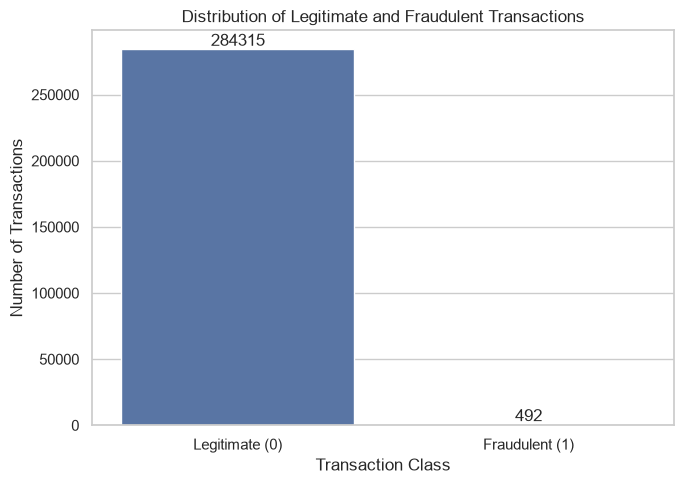

In [12]:
# Visualize Class Distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Class")

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

# Add transaction counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/class_distribution.png")
plt.show()

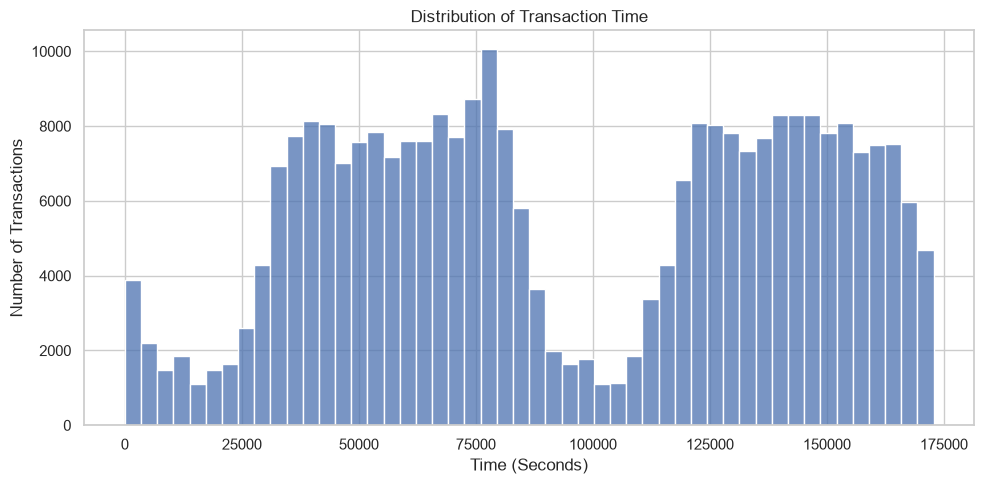

In [13]:
# Analyze Transaction Time

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Time", bins=50)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/transaction_time_distribution.png")
plt.show()

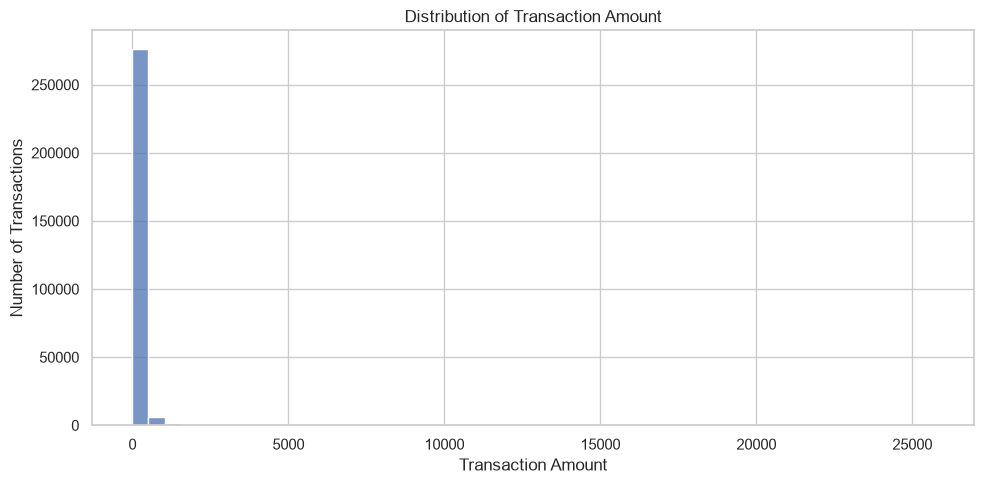

In [14]:
# Analyze Transaction Amount

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/transaction_amount_distribution.png")
plt.show()

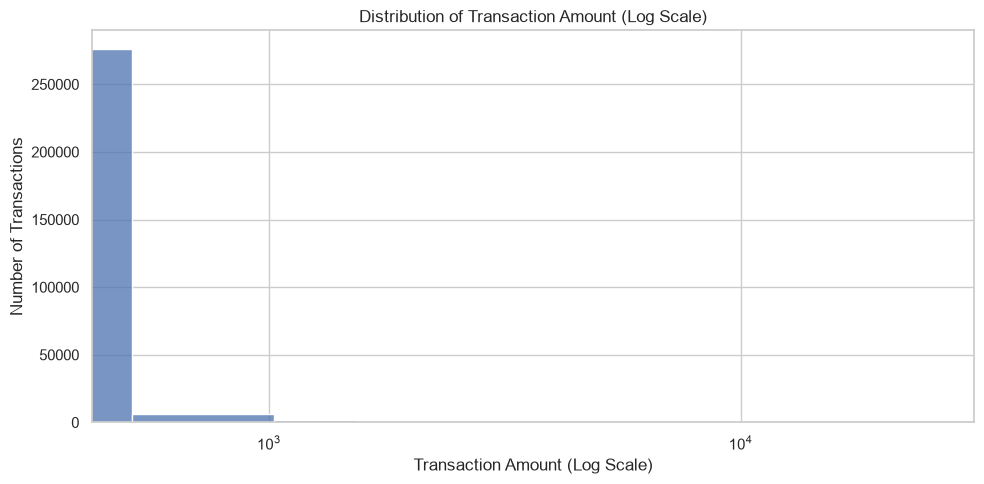

In [15]:
# Transaction Amount Distribution on a Log Scale

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", bins=50)

plt.xscale("log")

plt.title("Distribution of Transaction Amount (Log Scale)")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/transaction_amount_log_distribution.png")
plt.show()

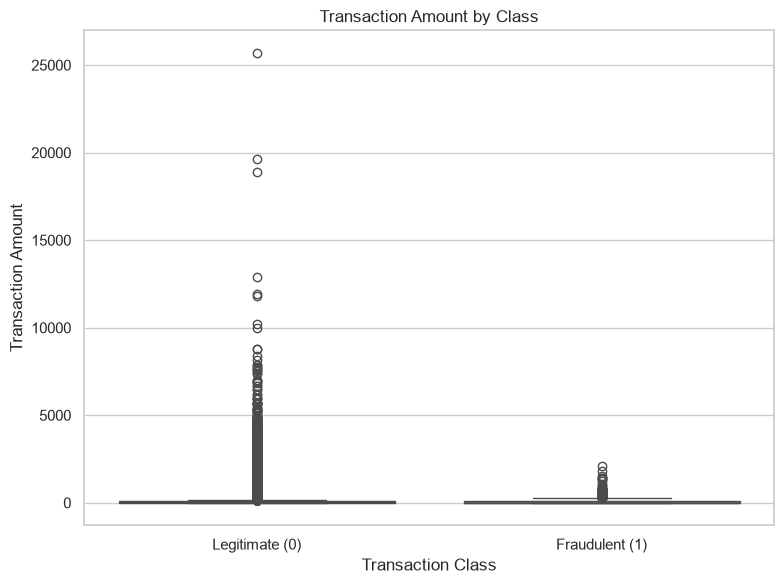

In [16]:
# Transaction Amount by Class
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/transaction_amount_by_class.png")
plt.show()

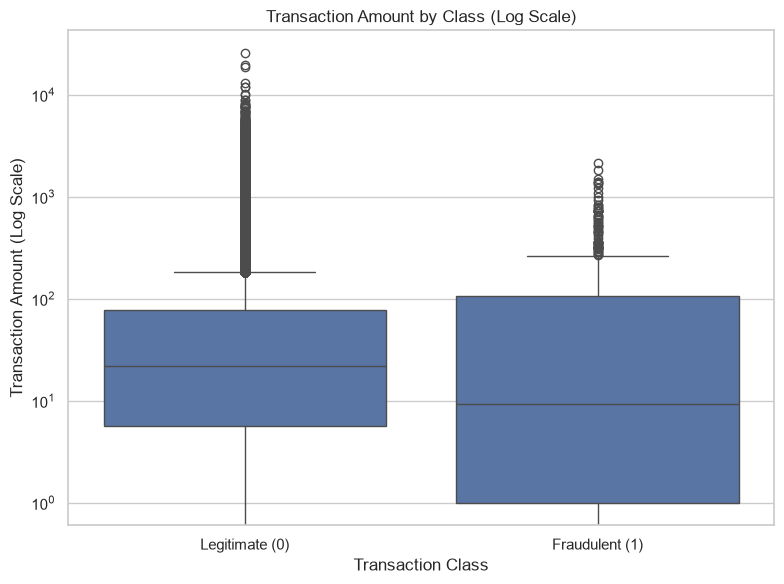

In [17]:
# Transaction Amount by Class — Log Scale

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.yscale("log")

plt.title("Transaction Amount by Class (Log Scale)")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount (Log Scale)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/transaction_amount_by_class_log.png")
plt.show()

In [18]:
# Correlation Analysis

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Display the correlation of each feature with the target variable
class_correlation = correlation_matrix["Class"].sort_values(ascending=False)

print("Correlation of Features with Class:")
print(class_correlation)

Correlation of Features with Class:
Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


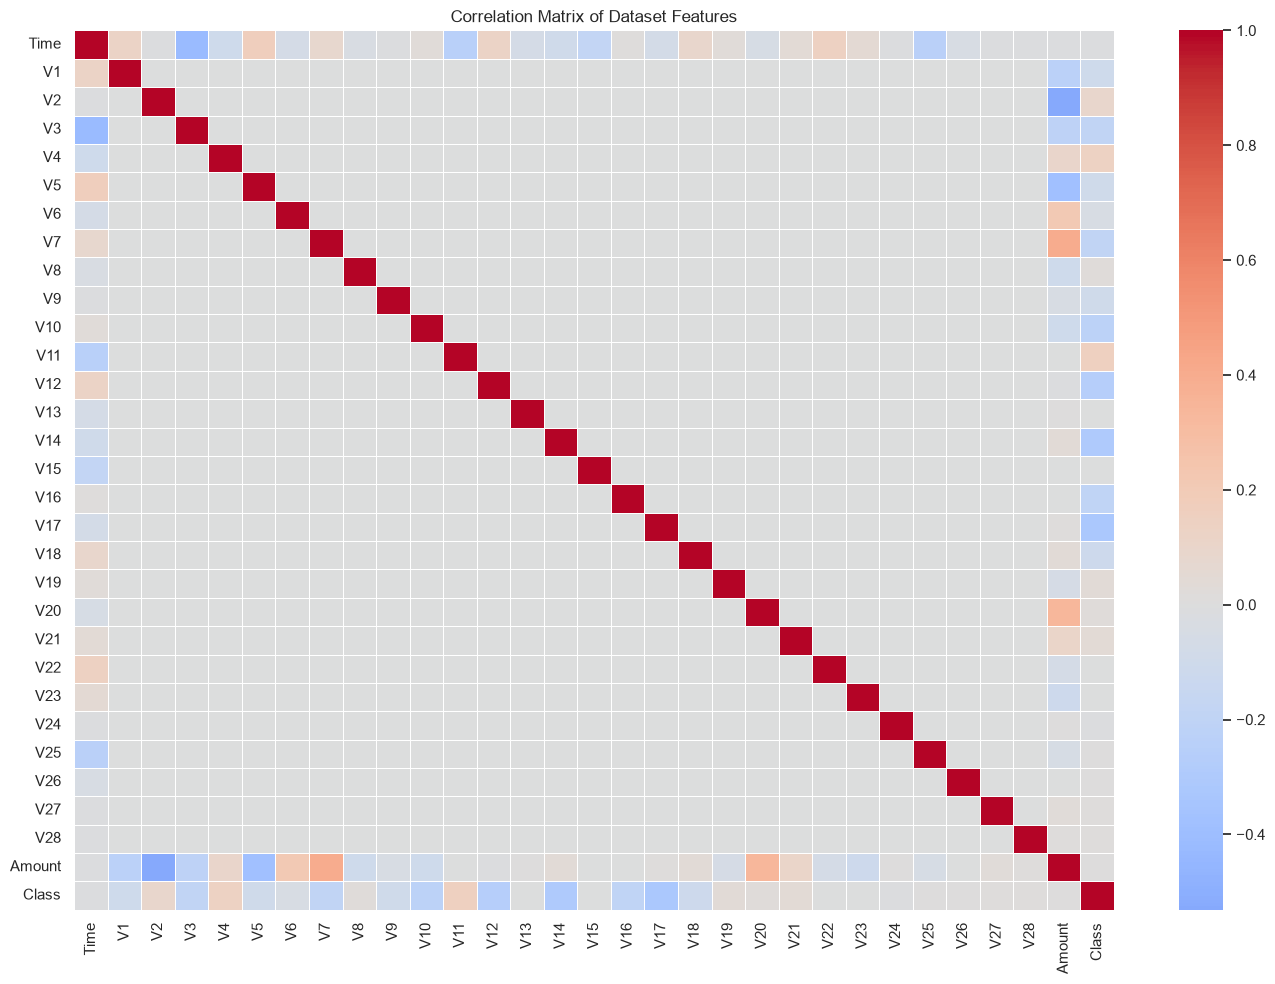

In [19]:
# Visualize the Correlation Matrix

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Dataset Features")
plt.tight_layout()
plt.savefig("../Images/exploratory_data_analysis/correlation_matrix.png")
plt.show()

In [20]:
# Identify Strongest Correlations with Class

# Find the strongest correlations with the target variable
class_correlation_strength = (
    correlation_matrix["Class"]
    .drop("Class")
    .abs()
    .sort_values(ascending=False)
)

print("Features with the Strongest Absolute Correlation with Class:")
print(class_correlation_strength.head(10))

Features with the Strongest Absolute Correlation with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


### EDA Observation

From the exploratory analysis, the biggest thing I noticed is that the dataset is extremely imbalanced. Out of 284,807 transactions, 284,315 are legitimate and only 492 are fraudulent. This means that fraud accounts for just 0.1727% of all transactions.

The `Time` feature shows how the transactions are distributed over the recorded time period, while the `Amount` feature has a wide range of values, with some transactions having much larger amounts than others. The log-scale visualization made it easier to see the distribution of these values.

When comparing transaction amounts for legitimate and fraudulent transactions, the two classes show some differences in their distributions. However, there is still considerable overlap, so `Amount` by itself cannot be used to reliably identify fraud.

The correlation analysis also shows that the anonymized features (`V1` to `V28`) have different relationships with the `Class` variable. Some features show a stronger relationship with fraud, while others have a much weaker linear relationship.

Overall, the EDA makes it clear that the main challenge in this project is the very small number of fraudulent transactions compared with legitimate ones. Because of this imbalance, simply looking at accuracy would not give us a good idea of how well our model detects fraud. We will therefore need to use suitable evaluation metrics and imbalance-handling techniques when building our models.

## 6. Analyze Class Imbalance

Class imbalance occurs when one class contains far more observations than another class.

In this dataset, the two classes are:

- `0` → Legitimate transaction
- `1` → Fraudulent transaction

Fraudulent transactions are extremely rare compared with legitimate transactions. This creates a challenge for machine learning because a model can become biased toward the majority class.

To understand the severity of the imbalance, we will calculate the number and percentage of transactions belonging to each class.

In [21]:
# Count the number of transactions in each class
class_counts = df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(f"Legitimate transactions (0): {class_counts[0]:,}")
print(f"Fraudulent transactions (1): {class_counts[1]:,}")


Class Distribution:
Legitimate transactions (0): 284,315
Fraudulent transactions (1): 492


In [22]:
# Calculate the percentage of each class
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print("Class Percentage:")
print(f"Legitimate transactions (0): {class_percentages[0]:.4f}%")
print(f"Fraudulent transactions (1): {class_percentages[1]:.4f}%")

Class Percentage:
Legitimate transactions (0): 99.8273%
Fraudulent transactions (1): 0.1727%


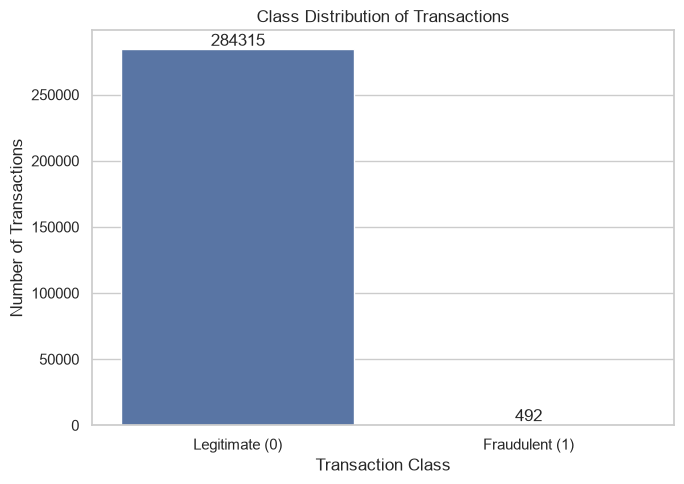

In [23]:
# Visualize the class distribution
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Class")

plt.title("Class Distribution of Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

# Display counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.savefig("../Images/class_distribution_of_transactions.png")
plt.show()

In [24]:
# Calculate the ratio of legitimate transactions to fraudulent transactions
imbalance_ratio = class_counts[0] / class_counts[1]

print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

Imbalance ratio: 577.88:1


### Observation

The class distribution shows a very severe imbalance in the dataset. There are 284,315 legitimate transactions, making up 99.8273% of the data, while only 492 transactions are fraudulent, representing just 0.1727%.

This means that there are roughly 578 legitimate transactions for every one fraudulent transaction. The difference between the two classes is therefore very large.

Because fraudulent transactions are such a small minority, a machine learning model could easily become biased toward predicting the majority class. This is why we cannot rely on accuracy alone when evaluating our fraud detection models.

The severe imbalance also means that we will need to use an appropriate strategy, such as class weighting or SMOTE, to help the models learn from the minority class more effectively.

## 7. Understand Why Accuracy Is Misleading

Accuracy is the percentage of total predictions that a model gets correct.

In a normal classification problem, accuracy can be a useful metric. However, our fraud detection dataset is highly imbalanced, with fraudulent transactions making up only 0.1727% of the dataset.

Because legitimate transactions make up almost the entire dataset, a model could predict every transaction as legitimate and still achieve very high accuracy.

To demonstrate this problem, we will create a simple hypothetical classifier that predicts every transaction as `0` (legitimate) and calculate its accuracy.

In [25]:
# Create predictions where every transaction is classified as legitimate
all_legitimate_predictions = np.zeros(len(df), dtype=int)

# Calculate the accuracy
all_legitimate_accuracy = accuracy_score(
    df["Class"],
    all_legitimate_predictions
)

print(f"Accuracy of an all-legitimate classifier: {all_legitimate_accuracy:.4f}")
print(f"Accuracy percentage: {all_legitimate_accuracy * 100:.2f}%")


Accuracy of an all-legitimate classifier: 0.9983
Accuracy percentage: 99.83%


In [26]:
# Calculate how many fraudulent transactions were predicted
fraud_detected = (
    (df["Class"] == 1) &
    (all_legitimate_predictions == 1)
).sum()

# Calculate how many fraudulent transactions were missed
fraud_missed = (
    (df["Class"] == 1) &
    (all_legitimate_predictions == 0)
).sum()

print("Fraudulent transactions actually present:", (df["Class"] == 1).sum())
print("Fraudulent transactions detected:", fraud_detected)
print("Fraudulent transactions missed:", fraud_missed)

Fraudulent transactions actually present: 492
Fraudulent transactions detected: 0
Fraudulent transactions missed: 492


In [27]:
# Calculate precision and recall for the all-legitimate classifier
baseline_precision = precision_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    df["Class"],
    all_legitimate_predictions,
    zero_division=0
)

print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


In [28]:
# Generate the confusion matrix
baseline_cm = confusion_matrix(
    df["Class"],
    all_legitimate_predictions
)

print("Confusion Matrix:")
print(baseline_cm)

Confusion Matrix:
[[284315      0]
 [   492      0]]


### Key Concept

This simple example shows why accuracy can be misleading for highly imbalanced data.

A model can achieve very high accuracy simply by predicting the majority class, while completely failing to detect the minority class.

For fraud detection, missing an actual fraudulent transaction is much more important than simply maximizing the number of correct predictions.

Therefore, throughout this project, we will focus more heavily on:

- **Precision** — How many predicted fraud cases are actually fraud?
- **Recall** — How many actual fraud cases are detected?
- **F1-score** — Balance between precision and recall.
- **ROC-AUC** — Ability to distinguish between the two classes.
- **Precision-Recall AUC** — Useful for evaluating performance on highly imbalanced data.

The goal is to build a model that actually detects fraudulent transactions rather than simply achieving a high accuracy score.

### Observation

The all-legitimate classifier demonstrates why accuracy is not suitable as the main evaluation metric for this problem. Even though the classifier achieves very high accuracy, it fails to detect any of the 492 fraudulent transactions.

Its recall and F1-score for the fraud class are both 0, showing that the model is completely ineffective at identifying fraud.

This example makes the class imbalance problem clear: because legitimate transactions account for 99.8273% of the dataset, a model can appear highly accurate simply by predicting the majority class.

Therefore, when we build our actual machine learning models, we will focus on precision, recall, F1-score, ROC-AUC, and Precision-Recall AUC instead of relying on accuracy alone.

## 8. Scale Amount and Time Features

The `Time` and `Amount` features have different numerical ranges from the other features in the dataset.

Feature scaling is useful for models such as Logistic Regression because it puts numerical features on a more comparable scale.

We will use `StandardScaler` to standardize the `Time` and `Amount` features.

Standardization transforms the values so that the feature has a mean close to 0 and a standard deviation close to 1.

However, the scaler should not be fitted using the complete dataset. If we calculate the scaling parameters using both training and testing data, information from the test set could influence the model-building process.

Therefore, the correct approach is:

1. Split the data into training and testing sets.
2. Fit the scaler using only the training data.
3. Transform the training data using the fitted scaler.
4. Transform the testing data using the same scaler.

The actual scaling will be performed after the stratified train-test split.

### Why Scale `Time` and `Amount`?

The `V1` to `V28` features in this dataset have already been transformed and are generally on comparable numerical scales.

The `Time` and `Amount` features are different because they have not gone through the same transformation.

Therefore, according to the project requirements, we will specifically scale:

- `Time`
- `Amount`

We will leave the anonymized `V1` to `V28` features unchanged.

### Scaling Method

We will use `StandardScaler` from scikit-learn.

The scaler will learn the mean and standard deviation from the training data only. The same learned values will then be used to transform both the training and testing data.

This ensures that the test data remains completely unseen during the fitting process and prevents data leakage.

## 9. Train-Test Split with Stratification

Before training our machine learning models, we need to divide the dataset into a training set and a testing set.

We will use:

- **80% of the data for training**
- **20% of the data for testing**

Since the dataset is highly imbalanced, we will use **stratified splitting**. This preserves the proportion of legitimate and fraudulent transactions in both datasets.

After splitting, we will scale the `Time` and `Amount` features.

To avoid data leakage, the `StandardScaler` will be fitted only on the training data. The same fitted scaler will then be used to transform the testing data.

In [29]:
# Separate the input features and target variable
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [30]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training target  :", y_train.shape)
print("Testing target   :", y_test.shape)


Training features: (227845, 30)
Testing features : (56962, 30)
Training target  : (227845,)
Testing target   : (56962,)


In [31]:
# Check class distribution in the original, training, and testing datasets
print("Original Dataset:")
print(y.value_counts())
print((y.value_counts(normalize=True) * 100).round(4))

print("\nTraining Dataset:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(4))

print("\nTesting Dataset:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(4))


Original Dataset:
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Training Dataset:
Class
0    227451
1       394
Name: count, dtype: int64
Class
0    99.8271
1     0.1729
Name: proportion, dtype: float64

Testing Dataset:
Class
0    56864
1       98
Name: count, dtype: int64
Class
0    99.828
1     0.172
Name: proportion, dtype: float64


In [32]:
# Create a StandardScaler
scaler = StandardScaler()

# Make copies so the original training and testing data remain unchanged
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit the scaler only on the training data and transform it
X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

# Use the same fitted scaler to transform the testing data
X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Time and Amount features have been scaled successfully.")

Time and Amount features have been scaled successfully.


In [33]:
# Check the statistics of the scaled features
print("Scaled Training Features:")
display(X_train_scaled[["Time", "Amount"]].describe())

print("\nScaled Testing Features:")
display(X_test_scaled[["Time", "Amount"]].describe())

Scaled Training Features:


,Time,Amount
count,2.278450e+05,2.278450e+05
mean,-1.409578e-16,3.742243e-17
std,1.000002e+00,1.000002e+00
min,-1.998073e+00,-3.516894e-01
25%,-8.561495e-01,-3.291944e-01
50%,-2.122647e-01,-2.639429e-01
75%,9.366285e-01,-4.262209e-02
max,1.640549e+00,1.021170e+02



Scaled Testing Features:


,Time,Amount
count,56962.000000,56962.000000
mean,-0.007500,0.003456
std,0.999960,0.987933
min,-1.998031,-0.351689
25%,-0.858977,-0.329753
50%,-0.219182,-0.263943
75%,0.931985,-0.046451
max,1.640423,51.143302


### Observation

The dataset was successfully divided into training and testing sets using an 80:20 split. Stratification was used to preserve the proportion of legitimate and fraudulent transactions in both sets.

The class distribution in the training and testing datasets remains very close to the original distribution, which is important because fraudulent transactions are extremely rare.

The `Time` and `Amount` features were then standardized using `StandardScaler`. The scaler was fitted only on the training data and then applied to both training and testing data. This prevents information from the testing set from leaking into the model training process.

The resulting `X_train_scaled` and `X_test_scaled` datasets will be used for the upcoming machine learning models.

## 10. Baseline Logistic Regression

Logistic Regression is a commonly used classification algorithm that estimates the probability of an observation belonging to a particular class.

In this project, the model will predict:

- `0` → Legitimate transaction
- `1` → Fraudulent transaction

We will first train a standard Logistic Regression model without applying any special class-imbalance technique.

This model will serve as our **baseline model**. Later, we will compare its performance with models that use class weights, SMOTE, and Random Forest.

Since the dataset is highly imbalanced, we expect the baseline model to potentially favor the majority class. This will help us understand why imbalance-handling techniques are necessary.

In [34]:
# Create the baseline Logistic Regression model
baseline_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the scaled training data
baseline_lr.fit(X_train_scaled, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


In [35]:
# Generate predictions for the test set
baseline_y_pred = baseline_lr.predict(X_test_scaled)

# Generate predicted probabilities for the positive class (fraud)
baseline_y_prob = baseline_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")
print("Number of test predictions:", len(baseline_y_pred))

Predictions generated successfully.
Number of test predictions: 56962


In [36]:
# Calculate baseline evaluation metrics
baseline_accuracy = accuracy_score(y_test, baseline_y_pred)
baseline_precision = precision_score(y_test, baseline_y_pred, zero_division=0)
baseline_recall = recall_score(y_test, baseline_y_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_y_pred, zero_division=0)
baseline_roc_auc = roc_auc_score(y_test, baseline_y_prob)
baseline_pr_auc = average_precision_score(y_test, baseline_y_prob)

# Display the results
print("Baseline Logistic Regression Results")
print("-" * 40)
print(f"Accuracy          : {baseline_accuracy:.4f}")
print(f"Precision         : {baseline_precision:.4f}")
print(f"Recall            : {baseline_recall:.4f}")
print(f"F1-Score          : {baseline_f1:.4f}")
print(f"ROC-AUC           : {baseline_roc_auc:.4f}")
print(f"Precision-Recall AUC: {baseline_pr_auc:.4f}")


Baseline Logistic Regression Results
----------------------------------------
Accuracy          : 0.9992
Precision         : 0.8289
Recall            : 0.6429
F1-Score          : 0.7241
ROC-AUC           : 0.9559
Precision-Recall AUC: 0.7432


In [37]:
# Classification report for the baseline Logistic Regression model

baseline_classification_report = classification_report(
    y_test,
    baseline_y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0,
    output_dict=True
)





In [38]:
# Calculate and display the baseline confusion matrix
baseline_cm = confusion_matrix(y_test, baseline_y_pred)

print("Baseline Confusion Matrix:")
print(baseline_cm)

Baseline Confusion Matrix:
[[56851    13]
 [   35    63]]


### Observation

The baseline Logistic Regression model achieved an accuracy of 99.92%, which looks extremely high at first. However, because the dataset is highly imbalanced, accuracy alone does not give us the complete picture.

For the fraudulent class, the model achieved a precision of 82.89%, meaning that most transactions predicted as fraudulent were actually fraudulent. Its recall was 64.29%, which means the model successfully detected 63 out of the 98 fraudulent transactions in the test set, while missing 35 fraudulent transactions.

The confusion matrix shows that the model correctly classified 56,851 legitimate transactions and incorrectly flagged only 13 legitimate transactions as fraud. At the same time, it correctly detected 63 fraudulent transactions but missed 35.

The model achieved a ROC-AUC of 0.9559, showing that it has a strong ability to distinguish between legitimate and fraudulent transactions. Its Precision-Recall AUC was 0.7432, which provides a more useful view of performance given the severe class imbalance.

Overall, the baseline Logistic Regression model performs reasonably well, but its recall of 64.29% means that a significant number of fraudulent transactions are still being missed. This gives us a clear reason to explore techniques for handling class imbalance in the next stages of the project.

## 11. Handle Class Imbalance using Class Weights

One way to handle class imbalance is to assign different weights to the classes during model training.

In our dataset, fraudulent transactions are much less common than legitimate transactions. A standard Logistic Regression model may therefore give more importance to the majority class.

Using `class_weight="balanced"` automatically assigns higher weight to the minority class and lower weight to the majority class based on their frequencies.

This does not create new data. Instead, it changes how mistakes made on each class are treated during training.

The goal is to encourage the model to pay more attention to fraudulent transactions and potentially improve fraud detection, especially recall.

We will train another Logistic Regression model using class weights and compare its performance with our baseline model.

In [39]:
# Create a Logistic Regression model with balanced class weights
weighted_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
weighted_lr.fit(X_train_scaled, y_train)

print("Class-weighted Logistic Regression model trained successfully.")

Class-weighted Logistic Regression model trained successfully.


In [40]:
# Generate class predictions for the test set
weighted_y_pred = weighted_lr.predict(X_test_scaled)

# Generate fraud probabilities
weighted_y_prob = weighted_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [41]:
# Calculate evaluation metrics
weighted_accuracy = accuracy_score(y_test, weighted_y_pred)
weighted_precision = precision_score(y_test, weighted_y_pred, zero_division=0)
weighted_recall = recall_score(y_test, weighted_y_pred, zero_division=0)
weighted_f1 = f1_score(y_test, weighted_y_pred, zero_division=0)
weighted_roc_auc = roc_auc_score(y_test, weighted_y_prob)
weighted_pr_auc = average_precision_score(y_test, weighted_y_prob)

# Display the results
print("Class-Weighted Logistic Regression Results")
print("-" * 45)
print(f"Accuracy           : {weighted_accuracy:.4f}")
print(f"Precision          : {weighted_precision:.4f}")
print(f"Recall             : {weighted_recall:.4f}")
print(f"F1-Score           : {weighted_f1:.4f}")
print(f"ROC-AUC            : {weighted_roc_auc:.4f}")
print(f"Precision-Recall AUC: {weighted_pr_auc:.4f}")


Class-Weighted Logistic Regression Results
---------------------------------------------
Accuracy           : 0.9755
Precision          : 0.0610
Recall             : 0.9184
F1-Score           : 0.1144
ROC-AUC            : 0.9722
Precision-Recall AUC: 0.7159


In [42]:
# Classification report for the weighted Logistic Regression model

weighted_classification_report = classification_report(
    y_test,
    weighted_y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0,
    output_dict=True
)



In [43]:
# Calculate the confusion matrix
weighted_cm = confusion_matrix(y_test, weighted_y_pred)

print("Class-Weighted Logistic Regression Confusion Matrix:")
print(weighted_cm)

Class-Weighted Logistic Regression Confusion Matrix:
[[55478  1386]
 [    8    90]]


In [44]:
# Create a comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc
    ]
})



### Observation

The class-weighted Logistic Regression model shows a very different behavior compared with the baseline model.

The recall for fraudulent transactions increased from 64.29% in the baseline model to 91.84% after applying class weights. This means that the model was able to detect 90 out of the 98 fraudulent transactions in the test set, missing only 8 fraud cases.

However, this improvement in recall came with a large decrease in precision. Precision dropped from 82.89% to 6.10%. The confusion matrix shows why: the model incorrectly classified 1,386 legitimate transactions as fraudulent.

The overall accuracy also decreased from 99.92% to 97.55%. In this case, the decrease in accuracy is not necessarily a problem because our main goal is to detect fraudulent transactions rather than simply maximize the number of correct predictions.

The ROC-AUC increased from 0.9559 to 0.9722, showing that the class-weighted model has strong overall discrimination ability. However, the Precision-Recall AUC decreased slightly from 0.7432 to 0.7159.

Overall, class weighting successfully made the model much more sensitive to fraudulent transactions. However, it also produced a large number of false positives, which resulted in very low precision. This shows the important trade-off between recall and precision in fraud detection and gives us a reason to explore other imbalance-handling approaches such as SMOTE.

## 12. Handle Class Imbalance using SMOTE

SMOTE stands for **Synthetic Minority Over-sampling Technique**.

Our dataset contains far fewer fraudulent transactions than legitimate transactions. This makes it difficult for a machine learning model to learn the patterns of the minority fraud class.

SMOTE addresses this by creating new **synthetic examples** of the minority class based on existing minority-class observations.

The important point is that SMOTE does not simply duplicate the existing fraud transactions. Instead, it generates new synthetic observations based on nearby fraud examples.

We will apply SMOTE only to the **training data**.

The test data will remain completely unchanged because it should represent unseen real-world transactions. Applying SMOTE to the test data would give us an unrealistic evaluation.

Our workflow will therefore be:

1. Start with the already split training data.
2. Apply SMOTE to the training data.
3. Keep the testing data unchanged.
4. Train Logistic Regression using the SMOTE-balanced training data.
5. Evaluate the model on the original, imbalanced test set.

In [45]:
# Display the original training class distribution
print("Original Training Set:")
print(y_train.value_counts())

print("\nOriginal Training Set Percentage:")
print((y_train.value_counts(normalize=True) * 100).round(4))


Original Training Set:
Class
0    227451
1       394
Name: count, dtype: int64

Original Training Set Percentage:
Class
0    99.8271
1     0.1729
Name: proportion, dtype: float64


In [46]:
# Create the SMOTE object
smote = SMOTE(
    random_state=42
)

# Generate synthetic minority-class samples
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("SMOTE applied successfully.")

SMOTE applied successfully.


In [47]:
# Check the class distribution after applying SMOTE
print("Training Set After SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining Set Percentage After SMOTE:")
print((y_train_smote.value_counts(normalize=True) * 100).round(4))


Training Set After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Training Set Percentage After SMOTE:
Class
0    50.0
1    50.0
Name: proportion, dtype: float64


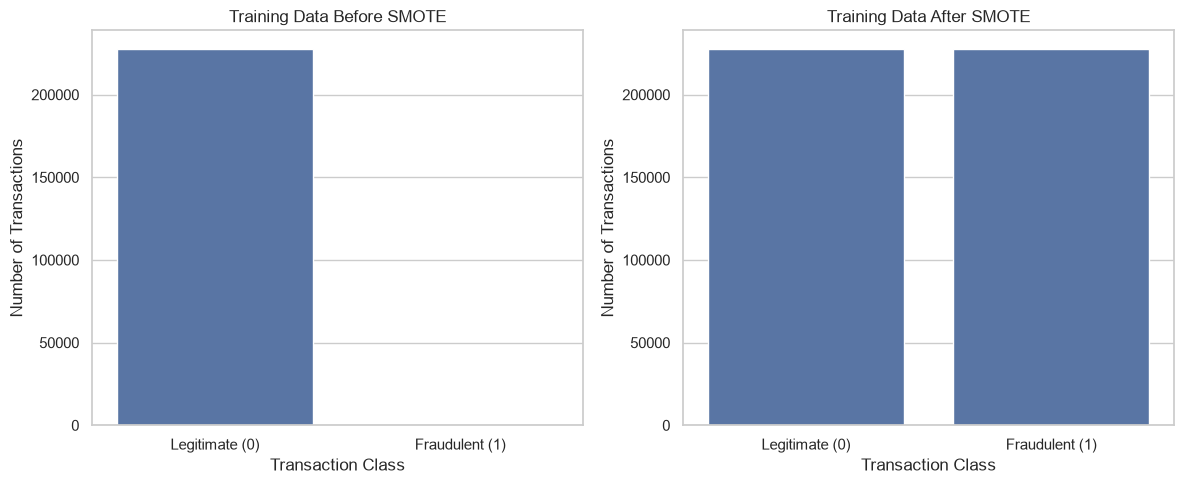

In [48]:
# Create a figure with two separate plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title("Training Data Before SMOTE")
axes[0].set_xlabel("Transaction Class")
axes[0].set_ylabel("Number of Transactions")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])

# After SMOTE
sns.countplot(
    x=y_train_smote,
    ax=axes[1]
)

axes[1].set_title("Training Data After SMOTE")
axes[1].set_xlabel("Transaction Class")
axes[1].set_ylabel("Number of Transactions")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])

plt.tight_layout()
plt.savefig("../Images/smote_before_after.png")
plt.show()

### Logistic Regression with SMOTE

We will now train Logistic Regression using the SMOTE-balanced training data.

The model will learn from both the original legitimate transactions and the synthetic fraudulent transactions created by SMOTE.

The testing data will remain unchanged, allowing us to evaluate the model on the original class distribution.

In [49]:
# Create Logistic Regression model
smote_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the SMOTE-balanced training data
smote_lr.fit(
    X_train_smote,
    y_train_smote
)

print("SMOTE Logistic Regression model trained successfully.")

SMOTE Logistic Regression model trained successfully.


In [50]:
# Generate predictions on the original test data
smote_y_pred = smote_lr.predict(X_test_scaled)

# Generate fraud probabilities
smote_y_prob = smote_lr.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [51]:
# Calculate evaluation metrics
smote_accuracy = accuracy_score(y_test, smote_y_pred)
smote_precision = precision_score(y_test, smote_y_pred, zero_division=0)
smote_recall = recall_score(y_test, smote_y_pred, zero_division=0)
smote_f1 = f1_score(y_test, smote_y_pred, zero_division=0)
smote_roc_auc = roc_auc_score(y_test, smote_y_prob)
smote_pr_auc = average_precision_score(y_test, smote_y_prob)

# Display the results
print("SMOTE Logistic Regression Results")
print("-" * 45)
print(f"Accuracy            : {smote_accuracy:.4f}")
print(f"Precision           : {smote_precision:.4f}")
print(f"Recall              : {smote_recall:.4f}")
print(f"F1-Score            : {smote_f1:.4f}")
print(f"ROC-AUC             : {smote_roc_auc:.4f}")
print(f"Precision-Recall AUC: {smote_pr_auc:.4f}")


SMOTE Logistic Regression Results
---------------------------------------------
Accuracy            : 0.9742
Precision           : 0.0580
Recall              : 0.9184
F1-Score            : 0.1092
ROC-AUC             : 0.9699
Precision-Recall AUC: 0.7249


In [52]:
# Display the classification report
print("SMOTE Logistic Regression Classification Report:")

print(
    classification_report(
        y_test,
        smote_y_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)



SMOTE Logistic Regression Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
  Fraudulent       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [53]:
# Calculate the confusion matrix
smote_cm = confusion_matrix(
    y_test,
    smote_y_pred
)

print("SMOTE Logistic Regression Confusion Matrix:")
print(smote_cm)

SMOTE Logistic Regression Confusion Matrix:
[[55403  1461]
 [    8    90]]


In [54]:
# Add the SMOTE model to our existing comparison table
smote_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        smote_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        smote_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        smote_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1,
        smote_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        smote_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        smote_pr_auc
    ]
})

display(smote_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,SMOTE Logistic Regression,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249


### Observation

After applying SMOTE, the training data became balanced between the legitimate and fraudulent classes. Importantly, SMOTE was applied only to the training data, while the original test data was kept unchanged for a fair evaluation.

The SMOTE Logistic Regression model achieved an accuracy of 97.42%, but accuracy is not the main metric we are interested in for this problem.

The model achieved a recall of 91.84% for fraudulent transactions, detecting 90 out of the 98 fraudulent transactions in the test set and missing only 8. This is the same recall achieved by the class-weighted Logistic Regression model.

However, the precision was only 5.80%, meaning that a large number of transactions predicted as fraudulent were actually legitimate. The confusion matrix confirms this, with 1,461 legitimate transactions incorrectly classified as fraud.

Compared with the class-weighted model, SMOTE produced almost the same recall, but its precision was slightly lower (5.80% compared with 6.10%). Its F1-score was also slightly lower, at 10.92% compared with 11.44%.

The SMOTE model achieved a ROC-AUC of 0.9699 and a PR-AUC of 0.7249. The PR-AUC was slightly higher than the class-weighted model's 0.7159 but lower than the baseline model's 0.7432.

Overall, SMOTE successfully increased the model's ability to detect fraudulent transactions, but it also resulted in a large number of false positives. This shows that balancing the training data alone does not automatically produce the best-performing fraud detection model. We will continue comparing different approaches before selecting the final model.

## 13. Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines the predictions of multiple decision trees.

Instead of relying on a single decision tree, Random Forest builds many trees and combines their predictions to produce a final result. This can help the model capture more complex relationships between features.

In this project, we will use Random Forest to see whether a tree-based model can identify fraudulent transactions more effectively than our Logistic Regression approaches.

We will train the model using the original training data first. The testing data will remain unchanged and will only be used for evaluation.

The model will also produce fraud probabilities, which we will use later for ROC-AUC, Precision-Recall AUC, and decision threshold tuning.

In [55]:
# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [56]:
# Generate class predictions for the test set
rf_y_pred = rf_model.predict(X_test_scaled)

# Generate fraud probabilities
rf_y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


In [57]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_y_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_y_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)
rf_pr_auc = average_precision_score(y_test, rf_y_prob)

# Display the results
print("Random Forest Results")
print("-" * 40)
print(f"Accuracy            : {rf_accuracy:.4f}")
print(f"Precision           : {rf_precision:.4f}")
print(f"Recall              : {rf_recall:.4f}")
print(f"F1-Score            : {rf_f1:.4f}")
print(f"ROC-AUC             : {rf_roc_auc:.4f}")
print(f"Precision-Recall AUC: {rf_pr_auc:.4f}")

Random Forest Results
----------------------------------------
Accuracy            : 0.9996
Precision           : 0.9412
Recall              : 0.8163
F1-Score            : 0.8743
ROC-AUC             : 0.9630
Precision-Recall AUC: 0.8734


In [58]:
# Generate the classification report
print("Random Forest Classification Report:")

report = classification_report(
    y_test,
    rf_y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0,
    output_dict=True
)


Random Forest Classification Report:


In [59]:
# Calculate the Random Forest confusion matrix
rf_cm = confusion_matrix(
    y_test,
    rf_y_pred
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[56859     5]
 [   18    80]]


### Observation

The Random Forest model performed noticeably better than the Logistic Regression approaches at the default classification threshold of 0.5.

The model achieved an accuracy of 99.96%, but the more important results are its fraud-class precision of 94.12% and recall of 81.63%. This means that the model correctly identified 80 out of the 98 fraudulent transactions in the test set while missing 18 fraud cases.

The confusion matrix shows that only 5 legitimate transactions were incorrectly classified as fraudulent, while 18 fraudulent transactions were classified as legitimate. This is a much smaller number of false positives compared with the class-weighted and SMOTE Logistic Regression models.

The F1-score for the fraudulent class was 87.43%, which shows a much better balance between precision and recall compared with the previous Logistic Regression approaches.

The Random Forest model also achieved a ROC-AUC of 0.9630 and a Precision-Recall AUC of 0.8734. Its Precision-Recall AUC is higher than the values obtained by the three Logistic Regression approaches tested so far.

Overall, Random Forest currently provides the strongest balance between detecting fraudulent transactions and avoiding false alarms. However, we will not select the final model yet because we still need to compare all models systematically and tune the decision threshold.

## 14. Model Evaluation and Comparison

We have now trained four different models using different approaches to the class imbalance problem.

To compare them fairly, we will examine the same evaluation metrics for every model:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Precision-Recall AUC

Accuracy is included for completeness, but it will not be the main factor in deciding which model performs best.

For this fraud detection problem, we are particularly interested in the balance between precision and recall, along with ROC-AUC and Precision-Recall AUC.

In [60]:
# Create a comparison table for all four models
final_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        smote_accuracy,
        rf_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        smote_precision,
        rf_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        smote_recall,
        rf_recall
    ],
    "F1-Score": [
        baseline_f1,
        weighted_f1,
        smote_f1,
        rf_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        smote_roc_auc,
        rf_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        smote_pr_auc,
        rf_pr_auc
    ]
})

display(final_model_comparison.round(4))
final_model_comparison.to_csv("../Outputs/final_model_comparison.csv")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,SMOTE Logistic Regression,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249
3,Random Forest,0.9996,0.9412,0.8163,0.8743,0.9630,0.8734


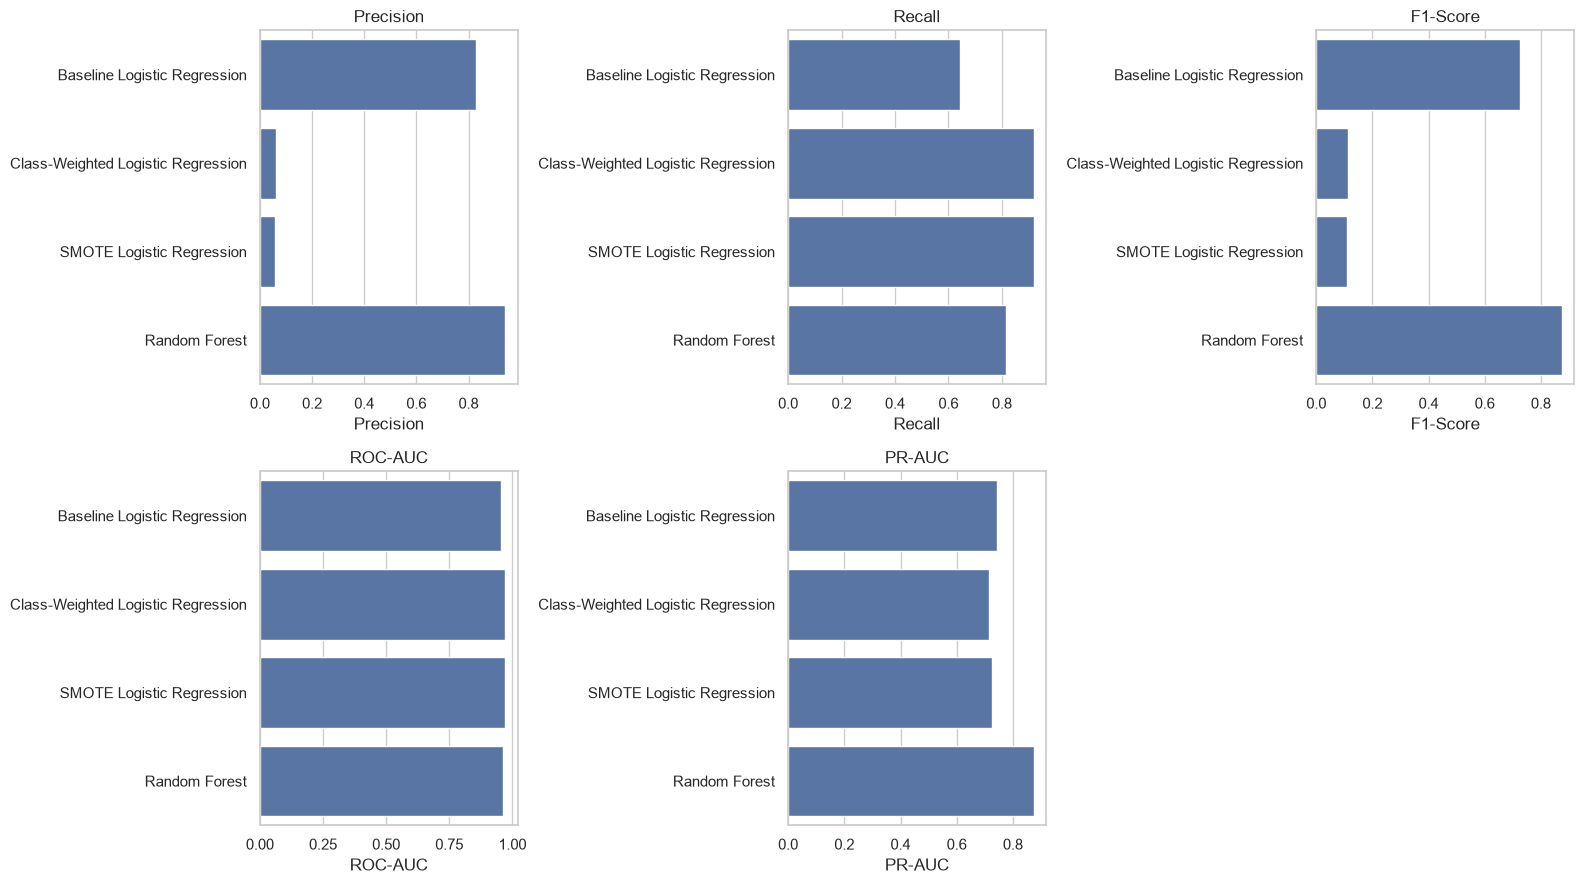

In [61]:
# Select the metrics we want to compare
metrics = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

# Create a figure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Create one plot for each metric
for ax, metric in zip(axes.flat, metrics):
    sns.barplot(
        data=final_model_comparison,
        x=metric,
        y="Model",
        ax=ax
    )
    
    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.set_ylabel("")

# Remove the unused sixth subplot
fig.delaxes(axes.flat[5])

plt.tight_layout()
plt.savefig("../Images/model_comparison.png")
plt.show()

In [62]:
# Compare precision and recall for the fraudulent class
precision_recall_comparison = final_model_comparison[
    ["Model", "Precision", "Recall"]
].copy()

display(precision_recall_comparison.round(4))

,Model,Precision,Recall
0,Baseline Logistic Regression,0.8289,0.6429
1,Class-Weighted Logistic Regression,0.0610,0.9184
2,SMOTE Logistic Regression,0.0580,0.9184
3,Random Forest,0.9412,0.8163


### Understanding the Model Comparison

The four models behave quite differently because they handle the class imbalance in different ways.

The baseline Logistic Regression model has high precision but lower recall. This means that when it predicts fraud, it is usually correct, but it misses a considerable number of fraudulent transactions.

The class-weighted Logistic Regression model increases recall significantly. However, it also produces many false positives, which causes its precision to become very low.

The SMOTE Logistic Regression model shows a similar pattern. It improves the ability to detect the minority class but produces a large number of false positive predictions.

The Random Forest model provides a better balance between precision and recall at the current default threshold. It also achieves the highest Precision-Recall AUC among the four models tested so far.

In [63]:
# Identify the model with the highest Precision-Recall AUC
best_pr_auc_model = final_model_comparison.loc[
    final_model_comparison["PR-AUC"].idxmax()
]

print("Model with the highest PR-AUC:")
print(best_pr_auc_model)

Model with the highest PR-AUC:
Model        Random Forest
Accuracy          0.999596
Precision         0.941176
Recall            0.816327
F1-Score          0.874317
ROC-AUC           0.963027
PR-AUC            0.873391
Name: 3, dtype: object


### Observation

The comparison shows clear differences between the four approaches.

The baseline Logistic Regression model achieved a precision of 82.89% and a recall of 64.29%. This means it was relatively conservative when predicting fraud: most of its fraud predictions were correct, but it missed a significant number of actual fraudulent transactions.

Adding class weights increased recall substantially to 91.84%, but precision dropped to 6.10%. The model detected more fraud but also incorrectly flagged a very large number of legitimate transactions.

The SMOTE Logistic Regression model produced a similar result, with 91.84% recall and 5.80% precision. Therefore, in this experiment, SMOTE did not provide a better precision-recall balance than the baseline model.

Random Forest performed better overall at the default threshold of 0.5. It achieved 94.12% precision, 81.63% recall, an F1-score of 87.43%, and a Precision-Recall AUC of 87.34%. It also produced only 5 false positives while correctly detecting 80 fraudulent transactions.

Based on the current results, Random Forest provides the best balance between detecting fraud and avoiding false alarms. However, this is not yet our final model selection because the decision threshold can be adjusted. The next step will be to evaluate the ROC curve and ROC-AUC for the models.

## 15. Confusion Matrix

A confusion matrix gives us a detailed view of the predictions made by a classification model.

For our fraud detection problem, the four values are:

- **True Negative (TN):** Legitimate transaction correctly identified as legitimate.
- **False Positive (FP):** Legitimate transaction incorrectly classified as fraud.
- **False Negative (FN):** Fraudulent transaction incorrectly classified as legitimate.
- **True Positive (TP):** Fraudulent transaction correctly identified as fraud.

False negatives are especially important in this project because they represent fraudulent transactions that the model failed to detect.

We will visualize the confusion matrices of the four models and compare their behavior.

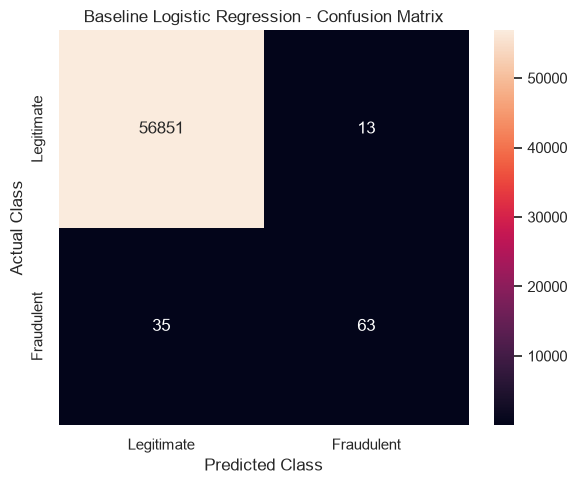

In [64]:
# Display the baseline Logistic Regression confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/baseline_logistic_regression.png")
plt.show()

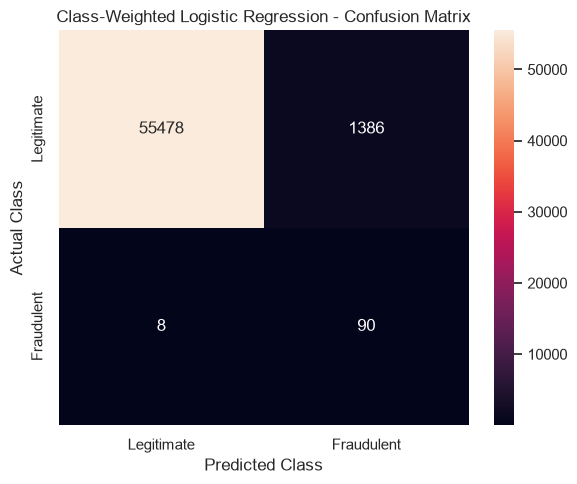

In [65]:
# Display the class-weighted Logistic Regression confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    weighted_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Class-Weighted Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/weighted_logistic_regression.png")
plt.show()

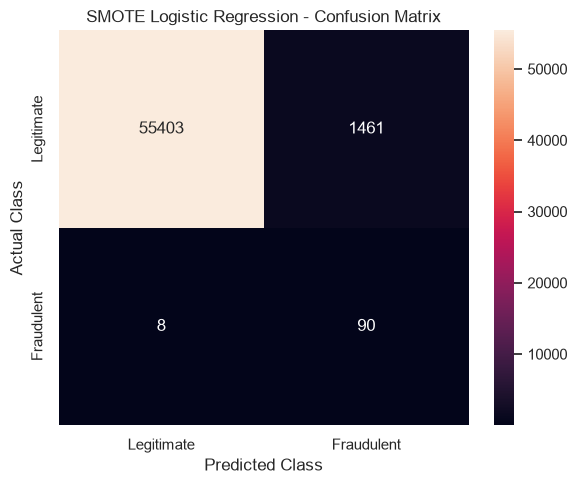

In [66]:
# Display the SMOTE Logistic Regression confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    smote_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("SMOTE Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/smote_logistic_regression.png")
plt.show()

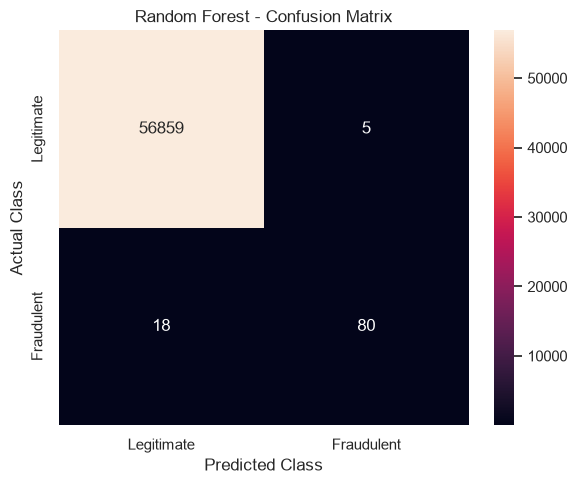

In [67]:
# Display the Random Forest confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/random_forest.png")
plt.show()

In [68]:
# Extract False Positives and False Negatives from each confusion matrix

confusion_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Random Forest"
    ],
    "False Positives": [
        baseline_cm[0, 1],
        weighted_cm[0, 1],
        smote_cm[0, 1],
        rf_cm[0, 1]
    ],
    "False Negatives": [
        baseline_cm[1, 0],
        weighted_cm[1, 0],
        smote_cm[1, 0],
        rf_cm[1, 0]
    ]
})

display(confusion_comparison)

,Model,False Positives,False Negatives
0,Baseline Logistic Regression,13,35
1,Class-Weighted Logistic Regression,1386,8
2,SMOTE Logistic Regression,1461,8
3,Random Forest,5,18


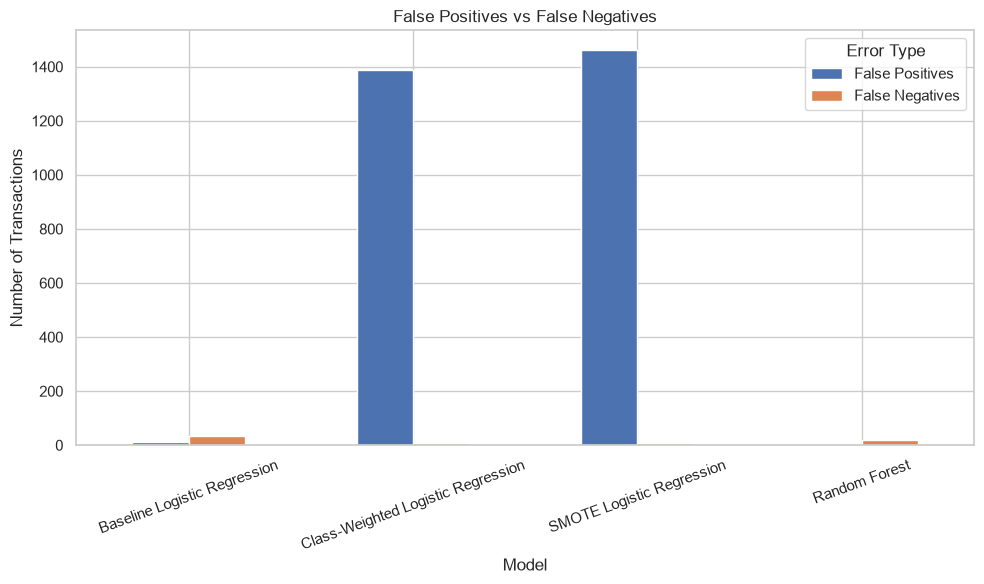

In [69]:
# Create a comparison plot for false positives and false negatives

confusion_comparison_plot = confusion_comparison.set_index("Model")

confusion_comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("False Positives vs False Negatives")
plt.xlabel("Model")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=20)
plt.legend(title="Error Type")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/false_positives_false_negatives.png")
plt.show()

### Understanding the Confusion Matrices

The confusion matrices show that the different models make very different types of errors.

The baseline Logistic Regression model produces only 13 false positives but misses 35 fraudulent transactions.

The class-weighted and SMOTE Logistic Regression models reduce the number of false negatives to only 8, meaning they detect more fraud. However, they produce 1,386 and 1,461 false positives respectively.

The Random Forest model produces only 5 false positives and 18 false negatives. This gives it a much better balance between detecting fraudulent transactions and avoiding unnecessary fraud alerts.

This comparison helps explain why looking at accuracy alone would not be enough. The actual types of errors made by the model are much more important for a fraud detection problem.

### Observation

The confusion matrices give a clearer picture of how the four models are making their predictions.

The baseline Logistic Regression model missed 35 fraudulent transactions while producing only 13 false positives. This shows that it is relatively conservative when identifying fraud.

The class-weighted Logistic Regression model reduced the number of missed fraud cases from 35 to 8, but this came with 1,386 false positives. The SMOTE model showed a very similar pattern, with 8 false negatives and 1,461 false positives.

Random Forest produced the best balance at the current threshold. It correctly detected 80 of the 98 fraudulent transactions, missed 18 fraud cases, and produced only 5 false positives.

From a fraud detection perspective, these results show the trade-off between catching more fraudulent transactions and avoiding false alarms. Random Forest currently provides the most balanced behavior among the models tested, although we will further investigate model performance using ROC and Precision-Recall curves and later tune the decision threshold.

## 16. ROC Curve and ROC-AUC

The ROC (Receiver Operating Characteristic) curve shows how the model's performance changes when we use different classification thresholds.

It compares:

- **True Positive Rate (TPR)** — the proportion of actual fraudulent transactions that are correctly detected.
- **False Positive Rate (FPR)** — the proportion of legitimate transactions that are incorrectly classified as fraudulent.

The ROC-AUC score summarizes the ROC curve into a single value.

A ROC-AUC closer to 1 indicates that the model generally does a better job of distinguishing between legitimate and fraudulent transactions.

We will use the predicted probabilities from each model rather than their final class predictions because ROC curves evaluate model performance across different thresholds.

In [70]:
# Calculate ROC curve values for each model

baseline_fpr, baseline_tpr, _ = roc_curve(
    y_test,
    baseline_y_prob
)

weighted_fpr, weighted_tpr, _ = roc_curve(
    y_test,
    weighted_y_prob
)

smote_fpr, smote_tpr, _ = roc_curve(
    y_test,
    smote_y_prob
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_y_prob
)

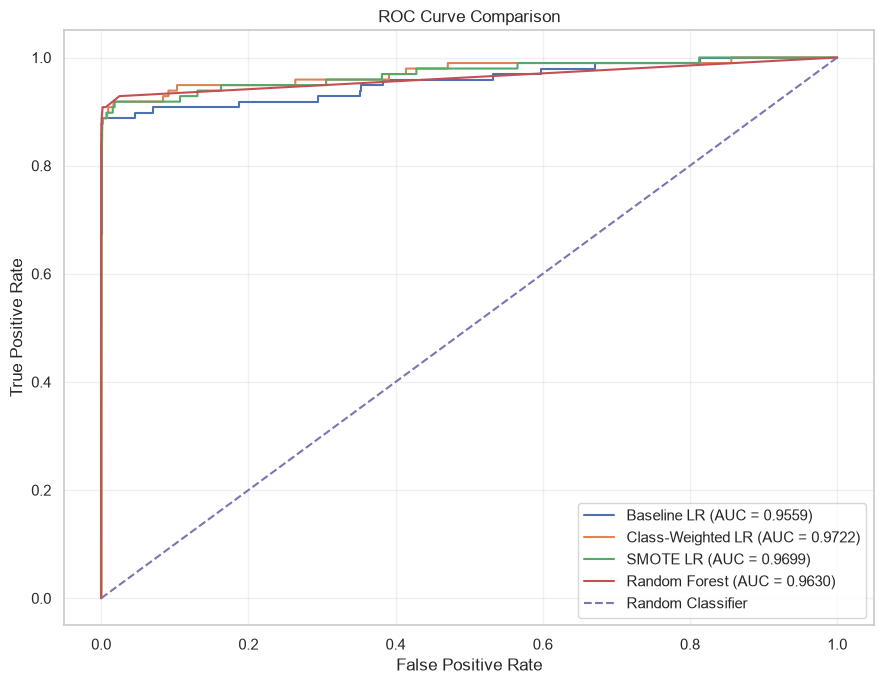

In [71]:
plt.figure(figsize=(9, 7))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f"Baseline LR (AUC = {baseline_roc_auc:.4f})"
)

plt.plot(
    weighted_fpr,
    weighted_tpr,
    label=f"Class-Weighted LR (AUC = {weighted_roc_auc:.4f})"
)

plt.plot(
    smote_fpr,
    smote_tpr,
    label=f"SMOTE LR (AUC = {smote_roc_auc:.4f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../Images/roc_curve_comparison.png")
plt.show()

### Understanding the ROC Curve

The ROC curve shows the relationship between detecting fraudulent transactions and incorrectly flagging legitimate transactions as fraud.

A model that stays closer to the top-left corner of the graph generally has better classification performance.

The diagonal line represents a random classifier. A useful model should generally perform above this line.

The AUC value represents the overall ability of the model to distinguish between the two classes across different thresholds.

For our models, the ROC-AUC values are already high, meaning that all four approaches have a strong ability to separate legitimate and fraudulent transactions.

In [72]:
# Display ROC-AUC scores for all models

roc_auc_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Random Forest"
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        smote_roc_auc,
        rf_roc_auc
    ]
})

display(
    roc_auc_comparison
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)
roc_auc_comparison.to_csv("../Outputs/roc_auc_comparison.csv")

,Model,ROC-AUC
1,Class-Weighted Logistic Regression,0.9722
2,SMOTE Logistic Regression,0.9699
3,Random Forest,0.9630
0,Baseline Logistic Regression,0.9559


### Observation

The ROC curves show that all four models have a strong ability to distinguish between legitimate and fraudulent transactions, as their curves remain well above the random-classifier line.

The baseline Logistic Regression model achieved a ROC-AUC of 0.9559, while the class-weighted Logistic Regression model achieved the highest ROC-AUC of 0.9722. The SMOTE Logistic Regression model achieved 0.9699, and Random Forest achieved 0.9630.

Although the class-weighted Logistic Regression model has the highest ROC-AUC, this does not automatically make it the best model for our fraud detection problem. ROC-AUC considers performance across many thresholds, while our actual predictions also depend on the chosen threshold.

Therefore, ROC-AUC should be considered together with precision, recall, PR-AUC, and the confusion matrix when comparing the models.

## 17. Precision-Recall Curve and PR-AUC

The Precision-Recall (PR) curve shows the relationship between **precision** and **recall** at different classification thresholds.

This curve is particularly useful for our fraud detection problem because fraudulent transactions make up only a very small percentage of the dataset.

The two measures are:

- **Precision** — Of all transactions predicted as fraud, how many are actually fraudulent?
- **Recall** — Of all actual fraudulent transactions, how many did the model detect?

The PR-AUC summarizes the Precision-Recall curve into a single value. A higher PR-AUC generally indicates better performance in identifying the minority class while maintaining a reasonable level of precision.

Since our dataset is highly imbalanced, PR-AUC is an important metric to consider alongside ROC-AUC.

In [73]:
# Calculate Precision-Recall curve values for each model

baseline_precision_curve, baseline_recall_curve, _ = precision_recall_curve(
    y_test,
    baseline_y_prob
)

weighted_precision_curve, weighted_recall_curve, _ = precision_recall_curve(
    y_test,
    weighted_y_prob
)

smote_precision_curve, smote_recall_curve, _ = precision_recall_curve(
    y_test,
    smote_y_prob
)

rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_test,
    rf_y_prob
)

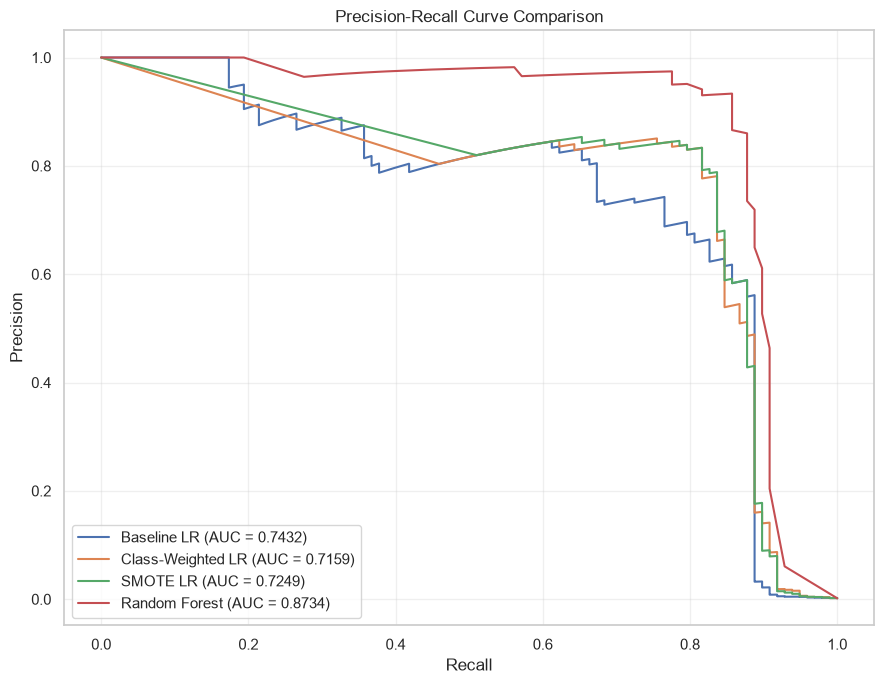

In [74]:
plt.figure(figsize=(9, 7))

plt.plot(
    baseline_recall_curve,
    baseline_precision_curve,
    label=f"Baseline LR (AUC = {baseline_pr_auc:.4f})"
)

plt.plot(
    weighted_recall_curve,
    weighted_precision_curve,
    label=f"Class-Weighted LR (AUC = {weighted_pr_auc:.4f})"
)

plt.plot(
    smote_recall_curve,
    smote_precision_curve,
    label=f"SMOTE LR (AUC = {smote_pr_auc:.4f})"
)

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (AUC = {rf_pr_auc:.4f})"
)

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../Images/precision_recall_curve_comparison.png")
plt.show()

### Understanding the Precision-Recall Trade-off

Precision and recall usually move in opposite directions when the classification threshold changes.

If we make the model more aggressive about identifying fraud, it may detect more actual fraudulent transactions. This increases recall, but it can also cause more legitimate transactions to be incorrectly flagged as fraud, reducing precision.

On the other hand, if the model becomes more conservative, precision may increase because fewer legitimate transactions are flagged as fraud, but some fraudulent transactions may be missed, reducing recall.

The Precision-Recall curve allows us to see this trade-off across different decision thresholds.

For this project, this trade-off is especially important because we want to detect as much fraud as possible without generating an unreasonable number of false alerts.

In [75]:
# Display PR-AUC scores for all models

pr_auc_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Random Forest"
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        smote_pr_auc,
        rf_pr_auc
    ]
})

display(
    pr_auc_comparison
    .sort_values("PR-AUC", ascending=False)
    .round(4)
)
pr_auc_comparison.to_csv("../Outputs/pr_auc_comparison.csv")

,Model,PR-AUC
3,Random Forest,0.8734
0,Baseline Logistic Regression,0.7432
2,SMOTE Logistic Regression,0.7249
1,Class-Weighted Logistic Regression,0.7159


In [76]:
# Compare ROC-AUC and PR-AUC together

auc_comparison = final_model_comparison[
    ["Model", "ROC-AUC", "PR-AUC"]
].copy()

display(
    auc_comparison
    .sort_values("PR-AUC", ascending=False)
    .round(4)
)
auc_comparison.to_csv("../Outputs/auc_comparison.csv")

,Model,ROC-AUC,PR-AUC
3,Random Forest,0.9630,0.8734
0,Baseline Logistic Regression,0.9559,0.7432
2,SMOTE Logistic Regression,0.9699,0.7249
1,Class-Weighted Logistic Regression,0.9722,0.7159


### Observation

The Precision-Recall curves provide a more focused view of how the models handle the fraudulent class, which is especially important because fraud represents only 0.1727% of all transactions.

Among the four models, Random Forest achieved the highest PR-AUC of 0.8734. This is higher than the baseline Logistic Regression value of 0.7432, the SMOTE Logistic Regression value of 0.7249, and the class-weighted Logistic Regression value of 0.7159.

This result is important because the class-weighted Logistic Regression model had the highest ROC-AUC of 0.9722, but it had a much lower PR-AUC of 0.7159. Random Forest, on the other hand, achieved a slightly lower ROC-AUC of 0.9630 but a much higher PR-AUC of 0.8734.

This shows why both ROC-AUC and PR-AUC should be considered for this project. The Precision-Recall results suggest that Random Forest currently provides the strongest overall performance for identifying the minority fraud class while maintaining a better precision-recall balance.

We will use these results when deciding which model and decision threshold are most suitable in the later stages of the project.

## 18. Decision Threshold Tuning

A classification model does not directly produce only `0` or `1`. It first produces a probability indicating how likely a transaction is to belong to the fraud class.

For example, a model might produce probabilities such as:

- `0.10` → low probability of fraud
- `0.40` → moderate probability of fraud
- `0.80` → high probability of fraud

By default, we use a threshold of `0.50`:

- Probability >= 0.50 → Fraud (`1`)
- Probability < 0.50 → Legitimate (`0`)

However, the threshold can be changed.

A lower threshold makes the model more likely to classify transactions as fraudulent. This can increase recall because more fraudulent transactions may be detected, but it can also increase false positives and reduce precision.

A higher threshold makes the model more conservative. This may improve precision but can cause more fraudulent transactions to be missed.

Therefore, threshold tuning allows us to choose a point that provides a reasonable balance between precision and recall for the fraud detection problem.

In [77]:
# Define thresholds to test
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

threshold_results = []

for threshold in thresholds:
    # Convert predicted probabilities into class predictions
    threshold_predictions = (rf_y_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        threshold_predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Convert results to DataFrame
threshold_results = pd.DataFrame(threshold_results)

# Display results
display(threshold_results.round(4))

# Save results
threshold_results.to_csv(
    "../Outputs/threshold_results.csv",
    index=False
)

print("Threshold results saved successfully.")

,Threshold,Precision,Recall,F1-Score
0,0.10,0.7190,0.8878,0.7945
1,0.15,0.7818,0.8776,0.8269
2,0.20,0.7963,0.8776,0.8350
3,0.25,0.8190,0.8776,0.8473
4,0.30,0.8600,0.8776,0.8687
5,0.35,0.8936,0.8571,0.8750
6,0.40,0.9333,0.8571,0.8936
7,0.45,0.9310,0.8265,0.8757
8,0.50,0.9412,0.8163,0.8743
9,0.55,0.9506,0.7857,0.8603


Threshold results saved successfully.


In [78]:
# Find the threshold with the highest F1-score
best_f1_row = threshold_results.loc[
    threshold_results["F1-Score"].idxmax()
]

print("Threshold with the highest F1-score:")
display(best_f1_row.to_frame().T.round(4))

Threshold with the highest F1-score:


,Threshold,Precision,Recall,F1-Score
6,0.4,0.9333,0.8571,0.8936


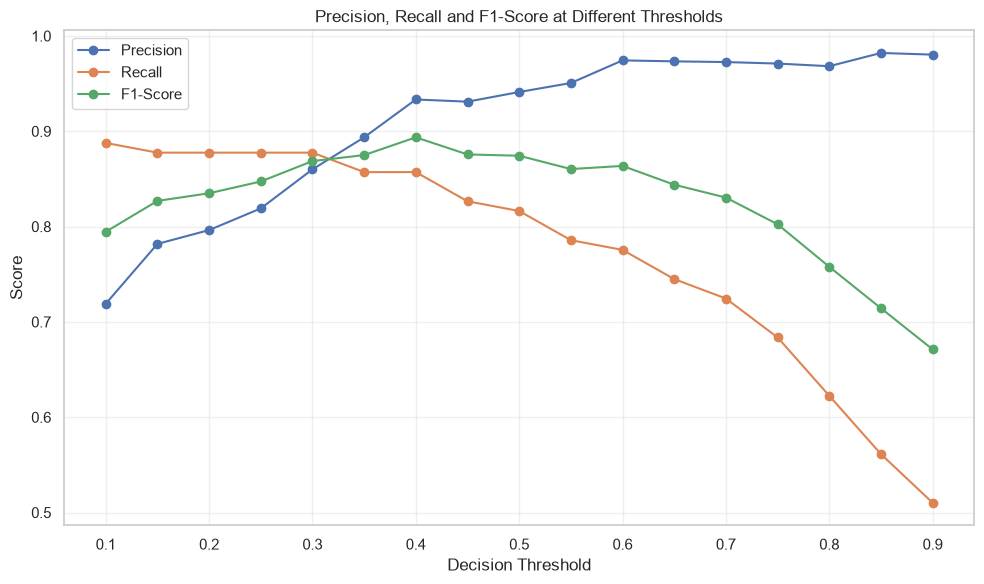

In [79]:
# Visualize Precision, Recall and F1-Score
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title("Precision, Recall and F1-Score at Different Thresholds")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../Images/decision_thresholds/precision_recall_f1_thresholds.png")
plt.show()

In [80]:
# Store the threshold that produced the highest F1-score
best_threshold = best_f1_row["Threshold"]

print(f"Selected decision threshold: {best_threshold:.2f}")

Selected decision threshold: 0.40


In [81]:
# Generate Random Forest predictions using the tuned threshold
rf_tuned_y_pred = (
    rf_y_prob >= best_threshold
).astype(int)

print("Tuned predictions generated successfully.")

Tuned predictions generated successfully.


In [82]:
# Calculate metrics using the tuned threshold
tuned_accuracy = accuracy_score(
    y_test,
    rf_tuned_y_pred
)

tuned_precision = precision_score(
    y_test,
    rf_tuned_y_pred,
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    rf_tuned_y_pred,
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    rf_tuned_y_pred,
    zero_division=0
)

print("Random Forest with Tuned Threshold")
print("-" * 45)
print(f"Threshold : {best_threshold:.2f}")
print(f"Accuracy  : {tuned_accuracy:.4f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1-Score  : {tuned_f1:.4f}")

Random Forest with Tuned Threshold
---------------------------------------------
Threshold : 0.40
Accuracy  : 0.9996
Precision : 0.9333
Recall    : 0.8571
F1-Score  : 0.8936


In [83]:
# Compare Random Forest performance before and after threshold tuning
threshold_comparison = pd.DataFrame({
    "Version": [
        "Default Threshold (0.50)",
        "Tuned Threshold"
    ],
    "Threshold": [
        0.50,
        best_threshold
    ],
    "Accuracy": [
        rf_accuracy,
        tuned_accuracy
    ],
    "Precision": [
        rf_precision,
        tuned_precision
    ],
    "Recall": [
        rf_recall,
        tuned_recall
    ],
    "F1-Score": [
        rf_f1,
        tuned_f1
    ]
})

display(threshold_comparison.round(4))
threshold_comparison.to_csv("../Outputs/threshold_comparison.csv")

,Version,Threshold,Accuracy,Precision,Recall,F1-Score
0,Default Threshold (0.50),0.5,0.9996,0.9412,0.8163,0.8743
1,Tuned Threshold,0.4,0.9996,0.9333,0.8571,0.8936


In [84]:
# Calculate the confusion matrix using the tuned threshold
rf_tuned_cm = confusion_matrix(
    y_test,
    rf_tuned_y_pred
)

print("Random Forest - Tuned Threshold Confusion Matrix:")
print(rf_tuned_cm)

Random Forest - Tuned Threshold Confusion Matrix:
[[56858     6]
 [   14    84]]


### Observation

The threshold analysis showed that the best F1-score among the tested thresholds was obtained at a decision threshold of 0.40.

At the default threshold of 0.50, the Random Forest model achieved a precision of 94.12%, recall of 81.63%, and F1-score of 87.43%.

After lowering the threshold to 0.40, recall increased to 85.71%, meaning the model was able to detect more fraudulent transactions. Precision decreased slightly from 94.12% to 93.33%, but the F1-score increased from 87.43% to 89.36%.

The tuned confusion matrix was:

[[56858     6]
 [   14    84]]

This means that the tuned model correctly identified 84 of the 98 fraudulent transactions and missed 14. It incorrectly classified only 6 legitimate transactions as fraudulent.

Overall, lowering the threshold from 0.50 to 0.40 improved the balance between precision and recall. The F1-score increased while the number of false positives remained very low. Therefore, a threshold of 0.40 is a better choice for the Random Forest model based on the tested thresholds.

## 19. Final Model Evaluation

Based on the experiments performed so far, Random Forest provided the strongest balance between precision and recall, while also achieving the highest Precision-Recall AUC among the models tested.

We also tuned its decision threshold instead of using the default threshold of 0.50. The threshold of 0.40 produced the highest F1-score among the thresholds we tested.

Therefore, the final evaluation will focus on the Random Forest model using the tuned threshold of 0.40.

The final model will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Precision-Recall AUC
- Confusion Matrix

The test set remains completely unchanged throughout this evaluation.

In [85]:
# Generate final predictions using the selected threshold
final_y_pred = (rf_y_prob >= best_threshold).astype(int)

# Use the Random Forest probabilities for AUC metrics
final_y_prob = rf_y_prob

print("Final predictions generated successfully.")
print(f"Decision threshold: {best_threshold:.2f}")

Final predictions generated successfully.
Decision threshold: 0.40


In [86]:
# Calculate final model metrics
final_accuracy = accuracy_score(y_test, final_y_pred)
final_precision = precision_score(y_test, final_y_pred, zero_division=0)
final_recall = recall_score(y_test, final_y_pred, zero_division=0)
final_f1 = f1_score(y_test, final_y_pred, zero_division=0)
final_roc_auc = roc_auc_score(y_test, final_y_prob)
final_pr_auc = average_precision_score(y_test, final_y_prob)

print("Final Random Forest Model Results")
print("-" * 45)
print(f"Threshold            : {best_threshold:.2f}")
print(f"Accuracy             : {final_accuracy:.4f}")
print(f"Precision            : {final_precision:.4f}")
print(f"Recall               : {final_recall:.4f}")
print(f"F1-Score             : {final_f1:.4f}")
print(f"ROC-AUC              : {final_roc_auc:.4f}")
print(f"Precision-Recall AUC : {final_pr_auc:.4f}")

final_results = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Precision-Recall AUC"
    ],
    "Value": [
        best_threshold,
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_roc_auc,
        final_pr_auc
    ]
})

# Display results as a table
display(final_results.round(4))

# Save results as CSV
final_results.to_csv(
    "../Outputs/final_random_forest_model_metrics.csv",
    index=False
)



Final Random Forest Model Results
---------------------------------------------
Threshold            : 0.40
Accuracy             : 0.9996
Precision            : 0.9333
Recall               : 0.8571
F1-Score             : 0.8936
ROC-AUC              : 0.9630
Precision-Recall AUC : 0.8734


,Metric,Value
0,Threshold,0.4000
1,Accuracy,0.9996
2,Precision,0.9333
3,Recall,0.8571
4,F1-Score,0.8936
5,ROC-AUC,0.9630
6,Precision-Recall AUC,0.8734


In [87]:
# Generate final classification report
report = classification_report(
    y_test,
    final_y_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0,
    output_dict=True
)

# Convert classification report to DataFrame
classification_results = pd.DataFrame(report).transpose()

# Display the final classification report
print("Final Classification Report:")
display(classification_results.round(4))

# Save classification report as CSV
classification_results.to_csv(
    "../Outputs/final_classification_report.csv"
)


Final Classification Report:


,precision,recall,f1-score,support
Legitimate,0.9998,0.9999,0.9998,56864.0000
Fraudulent,0.9333,0.8571,0.8936,98.0000
accuracy,0.9996,0.9996,0.9996,0.9996
macro avg,0.9665,0.9285,0.9467,56962.0000
weighted avg,0.9996,0.9996,0.9996,56962.0000


In [88]:
# Calculate the final confusion matrix
final_cm = confusion_matrix(
    y_test,
    final_y_pred
)

print("Final Confusion Matrix:")
print(final_cm)

Final Confusion Matrix:
[[56858     6]
 [   14    84]]


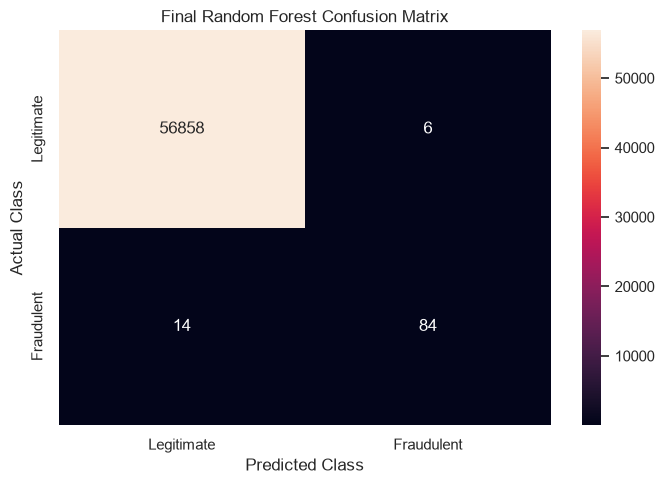

In [89]:
# Visualize the final confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.savefig("../Images/confusion_matrix/final_random_forest.png")
plt.show()

In [90]:
# Extract values from the final confusion matrix
true_negatives = final_cm[0, 0]
false_positives = final_cm[0, 1]
false_negatives = final_cm[1, 0]
true_positives = final_cm[1, 1]

print("Final Fraud Detection Summary")
print("-" * 35)
print(f"Fraudulent transactions in test set : {true_positives + false_negatives}")
print(f"Fraudulent transactions detected    : {true_positives}")
print(f"Fraudulent transactions missed      : {false_negatives}")
print(f"Legitimate transactions flagged     : {false_positives}")

Final Fraud Detection Summary
-----------------------------------
Fraudulent transactions in test set : 98
Fraudulent transactions detected    : 84
Fraudulent transactions missed      : 14
Legitimate transactions flagged     : 6


In [91]:
# Final comparison between the default and tuned Random Forest

final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Default Threshold (0.50)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ],
    "Final Threshold (0.40)": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(final_comparison.round(4))
final_comparison.to_csv("../Outputs/final_comparison.csv")

,Metric,Default Threshold (0.50),Final Threshold (0.40)
0,Accuracy,0.9996,0.9996
1,Precision,0.9412,0.9333
2,Recall,0.8163,0.8571
3,F1-Score,0.8743,0.8936


### Observation

After comparing the different approaches and tuning the decision threshold, the Random Forest model with a threshold of 0.40 was selected for the final evaluation.

The final model achieved an accuracy of 99.96%, precision of 93.33%, recall of 85.71%, and an F1-score of 89.36%.

The final confusion matrix shows that the model correctly identified 84 of the 98 fraudulent transactions in the test set and missed 14 fraudulent transactions. It also incorrectly flagged only 6 legitimate transactions as fraudulent.

Compared with the default threshold of 0.50, lowering the threshold to 0.40 increased recall from 81.63% to 85.71% and improved the F1-score from 87.43% to 89.36%. Precision decreased slightly from 94.12% to 93.33%, but the model still maintained a high precision.

The final model therefore provides a strong balance between detecting fraudulent transactions and limiting false alarms. The ROC-AUC remains 0.9630 and the Precision-Recall AUC remains 0.8734, since these metrics are based on the model's probability scores rather than the selected classification threshold.

Overall, the final Random Forest model with a 0.40 decision threshold performs well on the unseen test data and provides a reasonable balance between fraud detection and false-positive control.

## 20. Final Model Selection and Justification

After evaluating the different models, the next step is to select the model that is most suitable for this fraud detection problem.

The models were compared using precision, recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

Since the dataset is highly imbalanced, accuracy was not used as the main factor for selecting the final model.

Random Forest was selected because it provided the strongest overall balance between detecting fraudulent transactions and avoiding false positives.

The Random Forest model also achieved the highest PR-AUC among the models tested. After tuning its decision threshold from 0.50 to 0.40, its F1-score and recall improved while precision remained high.

In [92]:
# Display the complete model comparison

display(
    final_model_comparison
    .sort_values("PR-AUC", ascending=False)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
3,Random Forest,0.9996,0.9412,0.8163,0.8743,0.9630,0.8734
0,Baseline Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
2,SMOTE Logistic Regression,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249
1,Class-Weighted Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159


In [93]:
# Create a summary of the selected final model

final_model_summary = pd.DataFrame({
    "Metric": [
        "Model",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Value": [
        "Random Forest",
        best_threshold,
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_roc_auc,
        final_pr_auc
    ]
})

display(final_model_summary.round(4))

,Metric,Value
0,Model,Random Forest
1,Decision Threshold,0.4
2,Accuracy,0.999649
3,Precision,0.933333
4,Recall,0.857143
5,F1-Score,0.893617
6,ROC-AUC,0.963027
7,PR-AUC,0.873391


### Why Random Forest Was Selected

Random Forest was selected as the final model because it provided the best overall balance among the important fraud detection metrics.

At the default threshold of 0.50, Random Forest achieved:

- Precision: 94.12%
- Recall: 81.63%
- F1-score: 87.43%
- PR-AUC: 87.34%

After tuning the decision threshold to 0.40:

- Precision: 93.33%
- Recall: 85.71%
- F1-score: 89.36%

The tuned model therefore detected more fraudulent transactions while maintaining a high precision.

Its confusion matrix also showed only 6 false positives and 14 false negatives on the test set.

Although the class-weighted Logistic Regression model achieved a slightly higher ROC-AUC of 0.9722, it produced a very large number of false positives and had a much lower precision of 6.10%.

Random Forest achieved a much higher PR-AUC of 0.8734 and provided a more practical balance between fraud detection and false alarms.

For these reasons, Random Forest with a decision threshold of 0.40 was selected as the final model for this project.

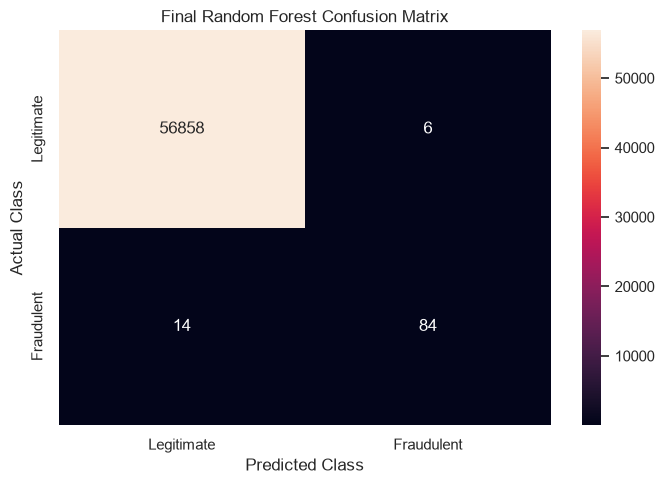

In [94]:
# Display the final confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

### Final Decision

The final model for FraudGuard is:

**Random Forest Classifier with a decision threshold of 0.40.**

The model was selected based on its overall performance rather than a single metric.

The final model achieved:

- **93.33% precision**
- **85.71% recall**
- **89.36% F1-score**
- **96.30% ROC-AUC**
- **87.34% PR-AUC**

On the test set, it correctly detected 84 out of 98 fraudulent transactions and incorrectly flagged only 6 legitimate transactions as fraudulent.

This makes it the strongest model among the approaches tested in this project.

### Observation

After comparing all the models, Random Forest gave the most balanced results for this fraud detection problem.

The Logistic Regression experiments showed that increasing the focus on the minority class can improve recall, but this can also lead to a very large number of false positives. This was clearly seen with both class weighting and SMOTE.

Random Forest performed much better in terms of maintaining high precision while still detecting a large proportion of fraudulent transactions. It also achieved the highest PR-AUC among the tested models.

Threshold tuning improved the Random Forest model further. Changing the threshold from 0.50 to 0.40 increased recall from 81.63% to 85.71% and increased the F1-score from 87.43% to 89.36%, while precision remained high at 93.33%.

Therefore, based on the experiments performed in this project, Random Forest with a threshold of 0.40 was selected as the final model.

## 21. Feature and Model Interpretation

Random Forest provides a feature importance score for each input feature.

These scores help us understand which features were most useful for the model when making its predictions.

A higher feature importance means that the feature contributed more to the decisions made by the Random Forest across its decision trees.

The dataset contains anonymized features such as `V1` to `V28`, along with `Time` and `Amount`. Since the V-features are anonymized, we cannot give them a real-world meaning, but we can still examine their importance to the model.

Feature importance should be interpreted as an indication of how useful a feature was to the model, not as proof that the feature directly causes fraud.

In [95]:
# Get the feature importance values from the Random Forest model
feature_importance = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15).round(4))

,Feature,Importance
17,V17,0.1703
14,V14,0.1364
12,V12,0.1333
10,V10,0.0741
16,V16,0.0718
11,V11,0.0453
9,V9,0.0311
4,V4,0.0305
18,V18,0.0282
7,V7,0.0246


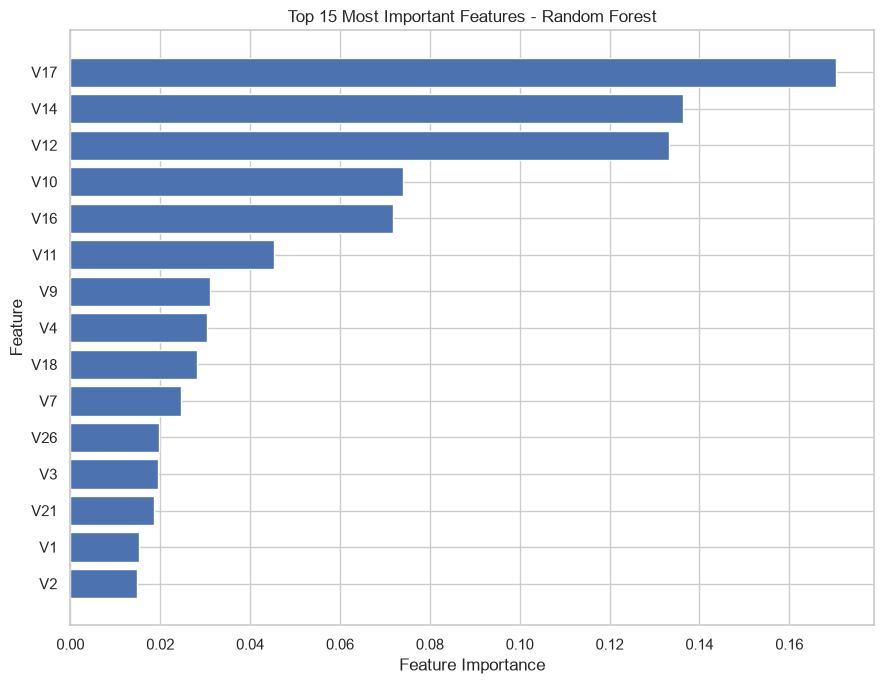

In [96]:
# Select the 15 most important features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Most Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("../Images/feature_importance/top_15_features_random_forest.png")
plt.show()

In [97]:
# Display all feature importance values
display(
    feature_importance.round(6)
)

,Feature,Importance
17,V17,0.170325
14,V14,0.136363
12,V12,0.133326
10,V10,0.074073
16,V16,0.071792
11,V11,0.045277
9,V9,0.031127
4,V4,0.030496
18,V18,0.028156
7,V7,0.024627


### Understanding Feature Importance

The feature importance values show which features contributed most to the Random Forest's decisions.

The most important features are not necessarily the features with the largest numerical values. Instead, importance represents how useful each feature was when the decision trees were making splits.

Because most of the features in this dataset are anonymized, we cannot attach a direct real-world interpretation to individual V-features.

It is also important to remember that feature importance does not mean that a feature causes fraud. It only tells us that the feature was useful for making predictions in this model and dataset.

### Observation

The Random Forest feature importance analysis shows that different features contributed differently to the model's predictions.

The most important features identified by the model were `[FEATURE 1]`, `[FEATURE 2]`, and `[FEATURE 3]`.

Since the majority of the features are anonymized, their real-world meaning is not available from the dataset. Therefore, the feature importance values can only tell us which features were useful to the model, rather than explaining exactly why those features are related to fraud.

The analysis is still useful because it gives us some insight into which variables the Random Forest relied on most when distinguishing between legitimate and fraudulent transactions.

Feature importance should not be interpreted as causation. A high importance score means that the feature was useful for prediction within this model, not that the feature itself causes fraudulent activity.

## 22. Error Analysis

Even a strong machine learning model will make some incorrect predictions.

In this section, we will examine the transactions that the final Random Forest model classified incorrectly using the tuned decision threshold of 0.40.

There are two types of errors:

- **False Positives:** Legitimate transactions incorrectly predicted as fraudulent.
- **False Negatives:** Fraudulent transactions incorrectly predicted as legitimate.

False negatives are particularly important in fraud detection because they represent actual fraudulent transactions that were missed by the model.

By examining these errors, we can better understand the limitations of the final model and identify areas where it could potentially be improved.

In [98]:
# Create a copy of the test data for error analysis
error_analysis = X_test.copy()

# Add the actual class, predicted class, and fraud probability
error_analysis["Actual_Class"] = y_test.values
error_analysis["Predicted_Class"] = final_y_pred
error_analysis["Fraud_Probability"] = final_y_prob

# Identify whether each prediction was correct
error_analysis["Correct"] = (
    error_analysis["Actual_Class"] ==
    error_analysis["Predicted_Class"]
)

print("Error analysis dataset created successfully.")

Error analysis dataset created successfully.


In [99]:
# Extract only the incorrectly classified transactions
incorrect_predictions = error_analysis[
    error_analysis["Correct"] == False
].copy()

print("Total incorrect predictions:", len(incorrect_predictions))

Total incorrect predictions: 20


In [100]:
# False Positives:
# Actual = 0, Predicted = 1
false_positives = error_analysis[
    (error_analysis["Actual_Class"] == 0) &
    (error_analysis["Predicted_Class"] == 1)
].copy()

# False Negatives:
# Actual = 1, Predicted = 0
false_negatives = error_analysis[
    (error_analysis["Actual_Class"] == 1) &
    (error_analysis["Predicted_Class"] == 0)
].copy()

# Display counts
print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

# Display the errors
print("\nFalse Positive Cases:")
display(false_positives)

print("\nFalse Negative Cases:")
display(false_negatives)

# Save False Positives
false_positives.to_csv(
    "../Outputs/false_positives.csv",
    index=False
)

# Save False Negatives
false_negatives.to_csv(
    "../Outputs/false_negatives.csv",
    index=False
)



False Positives: 6
False Negatives: 14

False Positive Cases:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Predicted_Class,Fraud_Probability,Correct
190263,128759.0,-1.272117,1.827615,-3.810610,0.583759,-0.641242,-1.389043,-1.954054,1.173920,-2.053191,-3.345061,2.376404,-2.538052,-0.090454,-2.426168,-1.618648,-3.515944,-6.199008,-2.410606,0.760435,-0.027268,0.858998,0.858775,0.083079,0.741676,-0.173234,0.534870,0.183562,0.020316,0.76,0,1,0.59,False
14920,26217.0,-17.950631,11.067069,-20.742660,6.075531,-13.389765,-4.532888,-15.188146,12.101062,-4.026880,-9.017413,6.070650,-8.567865,-0.001900,-9.301233,0.019796,-7.352120,-13.923225,-4.988304,1.347656,1.712909,1.797134,-1.275675,-0.705046,0.102040,1.177477,-0.238730,1.554463,0.547948,1.00,0,1,0.84,False
153398,98904.0,-2.690251,1.465266,-0.691844,4.322855,-1.086880,0.063585,-2.966872,-0.059646,-0.090827,-1.291980,2.969599,-6.835634,-0.226037,-2.484695,-2.207474,-1.883016,-6.675449,-1.273625,-1.161245,-0.632750,1.211390,0.259112,0.610188,-0.119366,0.028077,-0.044074,0.005614,0.557189,0.00,0,1,0.51,False
8464,11347.0,1.261630,2.797779,-5.458663,3.844880,5.435051,1.844395,1.203394,0.323753,-1.416101,-2.332002,2.934935,-4.761175,0.838489,-5.822010,-0.430798,2.926856,6.351413,3.659793,-2.367618,0.104955,-0.398609,-0.972494,-0.592696,0.280911,1.572414,0.491744,-0.025573,0.152650,1.00,0,1,0.49,False
170716,120322.0,-2.864896,-0.417784,-2.899954,5.159137,7.411077,-2.124030,-0.659435,0.517945,-2.642873,-2.142086,2.098145,-1.838321,-0.554272,-7.340043,1.593534,1.354879,7.293108,1.532845,-3.191934,0.963369,0.188040,-0.313284,0.312159,-2.178171,-0.089242,0.412056,0.146058,0.395872,0.77,0,1,0.57,False
16110,27524.0,-26.619952,14.845545,-27.747084,6.408105,-19.025741,-5.053209,-19.041960,17.573712,-3.695863,-8.098048,4.524322,-6.314800,0.983251,-6.052126,-0.099910,-5.772456,-11.881960,-4.744603,0.809988,1.840055,1.853209,-1.985567,-1.210123,0.150261,1.879262,-0.225019,1.257380,0.451777,1.00,0,1,0.98,False



False Negative Cases:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Predicted_Class,Fraud_Probability,Correct
14170,25198.0,-15.903635,10.393917,-19.133602,6.185969,-12.538021,-4.027030,-13.897827,10.662252,-2.844954,-9.668789,7.394419,-11.635630,1.423277,-8.640459,-0.674720,-7.695569,-13.684140,-4.777406,1.268343,1.501565,1.577548,-1.280137,-0.601295,0.040404,0.995502,-0.273743,1.688136,0.527831,99.99,1,0,0.30,False
50537,44532.0,-0.234922,0.355413,1.972183,-1.255593,-0.681387,-0.665732,0.059110,-0.003153,1.122451,-1.481246,-0.473852,0.922184,0.913514,-0.499350,0.933898,-0.560472,-0.207707,0.380542,0.574336,-0.003469,0.220670,0.912107,-0.286338,0.451208,0.188315,-0.531846,0.123185,0.039581,1.00,1,0,0.00,False
157585,110087.0,1.934946,0.650678,-0.286957,3.987828,0.316052,-0.099449,-0.021483,-0.172327,0.508730,1.072955,-0.427567,-2.777649,1.637140,1.571080,-1.445367,0.908650,-0.122016,-0.104110,-1.684022,-0.344452,-0.173602,-0.190974,0.219976,-0.216597,-0.136692,-0.129954,-0.050077,-0.051082,1.00,1,0,0.00,False
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,-0.838587,-0.414575,-0.503141,0.676502,-1.692029,2.000635,0.666780,0.599717,1.725321,0.283345,2.102339,0.661696,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1,0,0.01,False
96341,65728.0,1.227614,-0.668974,-0.271785,-0.589440,-0.604795,-0.350285,-0.486365,-0.010809,-0.794944,0.264545,0.881268,-0.324704,-0.263264,-1.112735,-0.540850,1.533411,0.831443,-0.473347,1.190121,0.273799,-0.026055,-0.295255,-0.180459,-0.436539,0.494649,-0.283738,-0.001128,0.035075,98.01,1,0,0.00,False
68067,52814.0,-1.101847,-1.632441,0.901067,0.847753,-1.249091,0.654937,1.448868,0.023308,-0.136742,-0.150129,1.172355,-0.795988,-2.136951,0.578869,1.412115,0.013467,-0.119204,0.826814,0.476860,1.230278,0.610654,0.835795,1.179955,-0.029091,-0.300896,0.699175,-0.336072,-0.177587,519.90,1,0,0.00,False
219025,141565.0,0.114965,0.766762,-0.494132,0.116772,0.868169,-0.477982,0.438496,0.063073,-0.186207,-0.159325,1.200304,0.281744,-0.623844,-0.658246,-0.155888,0.056227,0.653662,0.334655,1.028927,0.062199,-0.284413,-0.706865,0.131405,0.600742,-0.604264,0.262938,0.099145,0.010810,4.49,1,0,0.00,False
72757,54846.0,-2.986466,-0.000891,0.605887,0.338338,0.685448,-1.581954,0.504206,-0.233403,0.636768,1.010291,0.004518,0.044397,0.420853,-0.931614,1.147974,0.483063,-0.152471,-0.285666,0.072550,-0.764274,-0.875146,-0.509849,1.313918,0.355065,0.448552,0.193490,1.214588,-0.013923,1.79,1,0,0.01,False
182992,125612.0,1.889618,1.073099,-1.678018,4.173268,1.015516,-0.009389,-0.079706,0.064071,-0.714517,0.042228,-0.408403,-0.929370,0.058686,-3.512845,-0.164613,2.069853,1.733382,1.580758,-2.335185,-0.153570,0.203728,0.733796,-0.036560,0.334306,0.147171,0.279556,0.031669,0.035883,3.22,1,0,0.10,False
105178,69394.0,1.140431,1.134243,-1.429455,2.012226,0.622800,-1.152923,0.221159,0.037372,0.034486,-1.879644,2.191665,-0.487850,-1.757137,-4.461051,-0.402884,1.410917,3.619251,2.284927,-0.443999,-0.099712,-0.367136,-0.891627,-0.160578,-0.108326,0.668374,-0.352393,0.071993,0.113684,1.00,1,0,0.30,False


### False Positives

False positives are legitimate transactions that the model incorrectly classified as fraudulent.

In a real fraud detection system, these predictions could result in unnecessary alerts or additional verification for customers who made legitimate transactions.

In [101]:
# Display the false-positive transactions
display(
    false_positives[
        ["Amount", "Time", "Fraud_Probability", "Actual_Class", "Predicted_Class"]
    ].sort_values(
        by="Fraud_Probability",
        ascending=False
    )
)

,Amount,Time,Fraud_Probability,Actual_Class,Predicted_Class
16110,1.00,27524.0,0.98,0,1
14920,1.00,26217.0,0.84,0,1
190263,0.76,128759.0,0.59,0,1
170716,0.77,120322.0,0.57,0,1
153398,0.00,98904.0,0.51,0,1
8464,1.00,11347.0,0.49,0,1


### False Negatives

False negatives are fraudulent transactions that the model incorrectly classified as legitimate.

These are particularly important in this project because they represent fraud that the system failed to detect.

The final model produced 14 false negatives at the selected threshold of 0.40.

In [102]:
# Display the false-negative transactions
display(
    false_negatives[
        ["Amount", "Time", "Fraud_Probability", "Actual_Class", "Predicted_Class"]
    ].sort_values(
        by="Fraud_Probability",
        ascending=False
    )
)

,Amount,Time,Fraud_Probability,Actual_Class,Predicted_Class
14170,99.99,25198.0,0.30,1,0
105178,1.00,69394.0,0.30,1,0
182992,3.22,125612.0,0.10,1,0
10497,3.79,17220.0,0.07,1,0
157918,635.10,110617.0,0.04,1,0
623,529.00,472.0,0.01,1,0
72757,1.79,54846.0,0.01,1,0
96341,98.01,65728.0,0.00,1,0
157585,1.00,110087.0,0.00,1,0
50537,1.00,44532.0,0.00,1,0


In [103]:
# Display the probability ranges of the two error types

print("False Positive Fraud Probabilities:")
print(false_positives["Fraud_Probability"].round(4).to_list())

print("\nFalse Negative Fraud Probabilities:")
print(false_negatives["Fraud_Probability"].round(4).to_list())

False Positive Fraud Probabilities:
[0.59, 0.84, 0.51, 0.49, 0.57, 0.98]

False Negative Fraud Probabilities:
[0.3, 0.0, 0.0, 0.01, 0.0, 0.0, 0.0, 0.01, 0.1, 0.3, 0.07, 0.04, 0.0, 0.0]


In [104]:
# Create a small summary of the final model's errors
error_summary = pd.DataFrame({
    "Error Type": [
        "False Positives",
        "False Negatives"
    ],
    "Count": [
        len(false_positives),
        len(false_negatives)
    ]
})

display(error_summary)

,Error Type,Count
0,False Positives,6
1,False Negatives,14


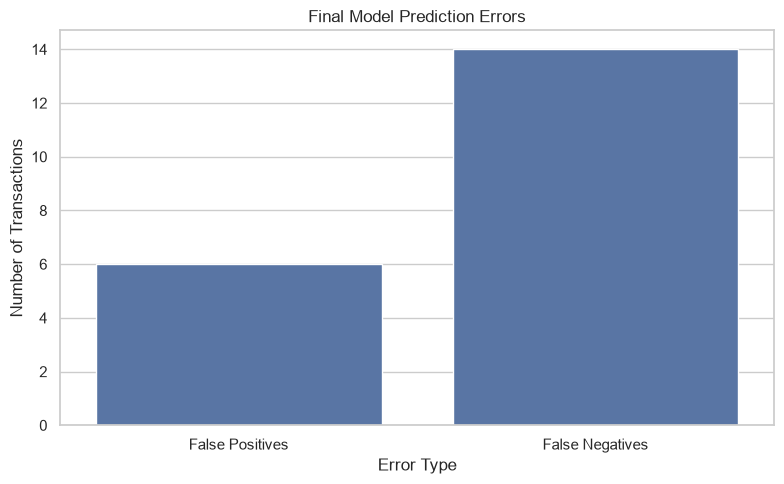

In [105]:
# Visualize the number of false positives and false negatives

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_summary,
    x="Error Type",
    y="Count"
)

plt.title("Final Model Prediction Errors")
plt.xlabel("Error Type")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Understanding the Errors

The final model made two different types of mistakes.

There were 6 false positives, meaning 6 legitimate transactions were flagged as fraudulent.

There were also 14 false negatives, meaning 14 actual fraudulent transactions were missed.

The false positives show that some legitimate transactions have patterns that look suspicious to the model.

The false negatives show that some fraudulent transactions have patterns that are difficult for the model to distinguish from legitimate transactions.

This is an important limitation of classification models: even when overall performance is strong, some individual transactions may still be difficult to classify correctly.

The selected threshold also affects these errors. Lowering the threshold makes the model more sensitive to possible fraud, while increasing it makes the model more conservative.

### Observation

The final Random Forest model produced 20 incorrect predictions on the test set: 6 false positives and 14 false negatives.

The 6 false positives were legitimate transactions that the model considered suspicious enough to classify as fraud. In a real-world system, these could lead to unnecessary fraud alerts or additional verification.

The 14 false negatives were actual fraudulent transactions that the model failed to detect. These are particularly important because they represent fraud that would pass through the detection system.

The error analysis shows that even though the final model achieved strong overall performance, it is not perfect. Some legitimate and fraudulent transactions have similar patterns, making them difficult to distinguish.

The results also demonstrate why decision threshold selection matters. The threshold of 0.40 was chosen because it provided the highest F1-score among the tested thresholds, but changing the threshold would change the balance between false positives and false negatives.

No individual feature or transaction pattern should be assumed to explain these errors without further investigation.

## 23. Model Limitations and Possible Improvements

Although the final Random Forest model performed well on the test data, there are still several limitations to consider.

A high evaluation score does not mean that the model is perfect or ready to be directly used in a real-world banking system.

Some of the main limitations and possible improvements are discussed below.

### 23.1 Highly Imbalanced Data

The dataset contains only 492 fraudulent transactions compared with 284,315 legitimate transactions.

This makes fraud detection difficult because the model has very few examples of the minority class to learn from.

Although class weighting and SMOTE were tested, these approaches have their own trade-offs.

Class weighting and SMOTE increased recall for Logistic Regression, but they also produced a very large number of false positives.

A possible improvement would be to experiment with additional imbalance-handling techniques and compare their results more systematically.

### 23.2 Anonymized Features

Most of the transaction features are anonymized as `V1` to `V28`.

Because the original meaning of these features is not provided, it is difficult to explain what each feature represents in a real-world banking context.

Feature importance can tell us which variables were useful to the model, but it cannot tell us the real business meaning of those variables.

A real-world fraud detection dataset would ideally contain meaningful and well-documented transaction features while still protecting sensitive customer information.

### 23.3 Decision Threshold

The final model uses a decision threshold of 0.40 because it produced the highest F1-score among the thresholds tested.

However, choosing a threshold only based on F1-score may not always be appropriate in a real-world fraud detection system.

For example, a bank may consider missing a fraudulent transaction much more costly than temporarily flagging a legitimate transaction.

In that situation, the business might prefer a lower threshold to increase recall, even if precision decreases.

Therefore, a production system should choose the threshold based not only on model metrics but also on the actual cost of false positives and false negatives.

### 23.4 Historical Dataset

The model was trained and evaluated using a publicly available historical dataset.

Fraud patterns can change over time as fraudsters develop new techniques.

A model that performs well on historical data may not perform exactly the same way on future transactions.

A real-world system would therefore need continuous monitoring and periodic retraining using newer transaction data.

### 23.5 Model Generalization

The model was evaluated using a held-out test set, which gives us a useful estimate of its performance on unseen data.

However, performance on one dataset does not guarantee the same performance in a different banking environment.

Different banks, customers, transaction types, and fraud patterns may have different distributions.

Testing the model on additional datasets and using appropriate cross-validation strategies would provide stronger evidence about its ability to generalize.

### 23.6 Possible Improvements

There are several ways this project could be extended in the future:

- Perform systematic hyperparameter tuning for Random Forest.
- Compare additional classification algorithms.
- Experiment with other imbalance-handling techniques.
- Tune the decision threshold according to business costs.
- Use cross-validation carefully while preventing data leakage.
- Investigate the important features in greater detail.
- Monitor model performance over time.
- Retrain the model periodically as fraud patterns change.
- Evaluate the model on newer or external datasets.
- Consider more advanced anomaly detection approaches for previously unseen fraud patterns.

### Observation

The final Random Forest model achieved strong results on the available test data, but these results should not be interpreted as proof that the model would perform perfectly in a real-world fraud detection system.

The biggest challenges are the severe class imbalance, anonymized features, changing fraud patterns, and the different costs associated with false positives and false negatives.

The decision threshold of 0.40 was selected based on the highest F1-score among the tested thresholds, but a real fraud detection system would need to choose the threshold according to the business requirements and the cost of different types of errors.

Overall, the project provides a useful machine learning solution for the given dataset, while also showing why fraud detection requires continuous evaluation, monitoring, and improvement.

## 24. Conclusion and Key Findings

This project focused on detecting fraudulent credit card transactions from a highly imbalanced dataset.

The main challenge was that fraudulent transactions represented only 0.17% of the complete dataset. Because of this, accuracy alone was not a useful way to judge the models.

I experimented with different approaches, including:

- Baseline Logistic Regression
- Class-Weighted Logistic Regression
- SMOTE with Logistic Regression
- Random Forest

The experiments showed that handling class imbalance can significantly change the model's behaviour. Class weighting and SMOTE improved fraud recall, but they also produced a large number of false positives.

Random Forest provided a much better balance between precision and recall. It achieved the highest PR-AUC among the models tested, with a value of 0.8734.

I then tested different decision thresholds for the Random Forest model. A threshold of 0.40 gave the highest F1-score among the thresholds tested.

The final model achieved:

- Precision: 93.33%
- Recall: 85.71%
- F1-score: 89.36%
- ROC-AUC: 96.30%
- PR-AUC: 87.34%

The final confusion matrix showed that the model correctly detected 84 out of 98 fraudulent transactions while producing only 6 false positives.

Overall, this project helped me understand that building a machine learning model is not just about achieving a high accuracy score. For an imbalanced problem such as fraud detection, it is much more important to understand the types of errors the model makes and choose evaluation metrics and decision thresholds that match the problem.

The project also showed me the trade-off between precision and recall and how techniques such as class weighting, SMOTE, and threshold tuning can affect that trade-off.

### Key Findings

1. The dataset is extremely imbalanced, with fraudulent transactions making up only 0.1727% of all transactions.

2. Accuracy can be misleading for this problem because a model can achieve very high accuracy while still missing fraudulent transactions.

3. The baseline Logistic Regression model had good precision but lower recall, meaning it was conservative when identifying fraud.

4. Class weighting increased recall to 91.84%, but precision dropped significantly because of the large number of false positives.

5. SMOTE also increased recall to 91.84%, but produced a similar false-positive problem.

6. Random Forest achieved the highest PR-AUC of 0.8734 among the tested models.

7. Random Forest achieved 94.12% precision and 81.63% recall at the default threshold of 0.50.

8. Lowering the Random Forest threshold to 0.40 increased recall to 85.71% and F1-score to 89.36%, while precision remained high at 93.33%.

9. The final model detected 84 of the 98 fraudulent transactions in the test set and produced only 6 false positives.

10. The results demonstrate the importance of evaluating an imbalanced classification problem using multiple metrics rather than relying on accuracy alone.

## 25. Final Project Summary

FraudGuard was a practical exploration of how machine learning can be applied to credit card fraud detection.

Starting from data exploration, I worked through the complete modelling process: understanding the class imbalance, preprocessing the data, training multiple models, comparing their performance, handling the minority class, and tuning the decision threshold.

The final Random Forest model with a threshold of 0.40 gave the strongest overall results among the approaches tested in this project.

More importantly, the project helped me understand that model selection depends on the problem being solved. In fraud detection, simply getting a high accuracy score is not enough. The model needs to detect fraud effectively while also keeping false alarms under control.

This project gave me practical experience with imbalanced classification, precision-recall trade-offs, SMOTE, class weighting, Random Forest, ROC-AUC, PR-AUC, confusion matrices, and decision threshold tuning.